Paper:              
Hahn 2023

Data:               
PRJNA946653, PRJNA875066

Sample Accession:   
SRR23914579, SRR23914578, SRR23914577, SRR23914576, SRR23914575, SRR23914574, SRR23914573, SRR23914572, SRR23914571, SRR23914455, SRR23914454, SRR23914453, SRR23914452, SRR23914451, SRR23914450, SRR21355398, SRR21355394, SRR21355390, SRR21355386, SRR21355397, SRR21355393, SRR21355389, SRR21355385, SRR21355401, SRR21355396, SRR21355392, SRR21355388

Task: 
Characterize rejuvenating intervention in cerebellum and how it is related to ageing signals

Pipeline: 
1. Load and organize the data
2. Filter genes
3. Explore the samples (PCA and clustering)
4. Differential expression (DE)
5. Interpret the gene lists (enrichment)
6. Connect interventions to aging


In [2]:
## Install packages 
install.packages(c("tidyverse", "ggrepel", "BiocManager", "pbapply", "gplots", "msigdbr", "viridis", "languageserver", "httpgd"))
BiocManager::install(c("biomaRt", "sva", "DESeq2", "edgeR", "tximport", "fgsea"))

Installiere Pakete nach 'C:/Users/hasch/AppData/Local/R/win-library/4.6'
(da 'lib' nicht spezifiziert)




  Es gibt eine Binärversion, jedoch ist der Quelltext neuer:
               binary source needs_compilation
languageserver 0.3.20 0.3.21              TRUE

  Binaries will be installed
package 'tidyverse' successfully unpacked and MD5 sums checked
package 'ggrepel' successfully unpacked and MD5 sums checked
package 'BiocManager' successfully unpacked and MD5 sums checked
package 'pbapply' successfully unpacked and MD5 sums checked
package 'gplots' successfully unpacked and MD5 sums checked
package 'msigdbr' successfully unpacked and MD5 sums checked
package 'viridis' successfully unpacked and MD5 sums checked
package 'languageserver' successfully unpacked and MD5 sums checked


Warning message:
"kann alte Installation von Paket 'languageserver' nicht entfernen"
Warning message in file.copy(savedcopy, lib, recursive = TRUE):
"Problem C:\Users\hasch\AppData\Local\R\win-library\4.6\00LOCK\languageserver\libs\x64\languageserver.dll nach C:\Users\hasch\AppData\Local\R\win-library\4.6\languageserver\libs\x64\languageserver.dll zu kopieren: Permission denied"
Warning message:
"'languageserver' wiederhergestellt"


package 'httpgd' successfully unpacked and MD5 sums checked

Die heruntergeladenen Binärpakete sind in 
	C:\Users\hasch\AppData\Local\Temp\RtmpUNNWwe\downloaded_packages


'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.r-project.org

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24 ucrt)

Warning message:
"package(s) not installed when version(s) same as or greater than current; use
  `force = TRUE` to re-install: 'biomaRt' 'sva' 'DESeq2' 'edgeR' 'tximport'
  'fgsea'"
Warning message in .available.both(repos, method, ...):
"Some listed binary packages have no source"
Installation paths not writeable, unable to update packages
  path: C:/Program Files/R/R-4.6.1/library
  packages:
    boot, class, cluster, codetools, foreign, KernSmooth, lattice, MASS,
    Matrix, mgcv, nlme, nnet, rpart, spatial, survival

Old packages: 'askpass', 'assertthat', 'babelgene', 'bit', 'bit64', 'blob',
  'brew', 'broom', 'bslib', 'cachem', 'callr', 'caTools', 'cellranger', 'cli',
  'clipr', 'collections', 'commonmark', 'confl

In [3]:
# switch off LaTeX
options(jupyter.rich_display = FALSE)


## Data import

The data has previously been preprocessed and is imported as an RSEM result.
Rows as features and columns as samples.

In [4]:
setwd("C:/Users/hasch/OneDrive/Documents/BSSE/Systems Genomics/Data Analysis Project 25.11.2026/Data")
options(jupyter.rich_display = FALSE)
library(dplyr)
library(ggplot2)

# Expression data: genes x samples
expr   <- as.matrix(read.csv("rsem_tpm.csv", row.names = 1, check.names = FALSE))
counts <- as.matrix(read.csv("rsem_expected_counts.csv", row.names = 1, check.names = FALSE))
counts <- counts[rownames(expr), colnames(expr)]

# Sample metadata, same order as the matrix columns
meta <- read.csv("samples.csv")
meta <- meta[match(colnames(expr), meta$SRR), ]

# Label each sample with the dataset it comes from
meta$dataset <- ifelse(meta$cohort == "Aging", "PRJNA875066", "PRJNA946653")

# Set the order of the groups (controls / young first)
meta$group <- factor(meta$group, levels = c("aging 3mo", "aging 18mo", "aging 21mo",
                                            "AL", "aDR", "PBS", "YMP"))

# Gene metadata, same order as the matrix rows
genes <- read.csv("genes_M39.csv")
meta_genes <- data.frame(gene_id = rownames(expr),
                         symbol  = genes$symbol[match(rownames(expr), genes$gene_id)])

table(meta$dataset, meta$group)



Attache Paket: 'dplyr'


Das folgende Objekt ist maskiert 'package:Biobase':

    combine


Das folgende Objekt ist maskiert 'package:matrixStats':

    count


Die folgenden Objekte sind maskiert von 'package:GenomicRanges':

    intersect, setdiff, union


Das folgende Objekt ist maskiert 'package:Seqinfo':

    intersect


Die folgenden Objekte sind maskiert von 'package:IRanges':

    collapse, desc, intersect, setdiff, slice, union


Die folgenden Objekte sind maskiert von 'package:S4Vectors':

    first, intersect, rename, setdiff, setequal, union


Die folgenden Objekte sind maskiert von 'package:BiocGenerics':

    combine, intersect, setdiff, setequal, union


Das folgende Objekt ist maskiert 'package:generics':

    explain


Die folgenden Objekte sind maskiert von 'package:stats':

    filter, lag


Die folgenden Objekte sind maskiert von 'package:base':

    intersect, setdiff, setequal, union




             
              aging 3mo aging 18mo aging 21mo AL aDR PBS YMP
  PRJNA875066         4          4          4  0   0   0   0
  PRJNA946653         0          0          0  4   5   3   3

In [5]:
dim(expr)


[1] 78289    27

## Comparison of transcriptomic profiles across samples


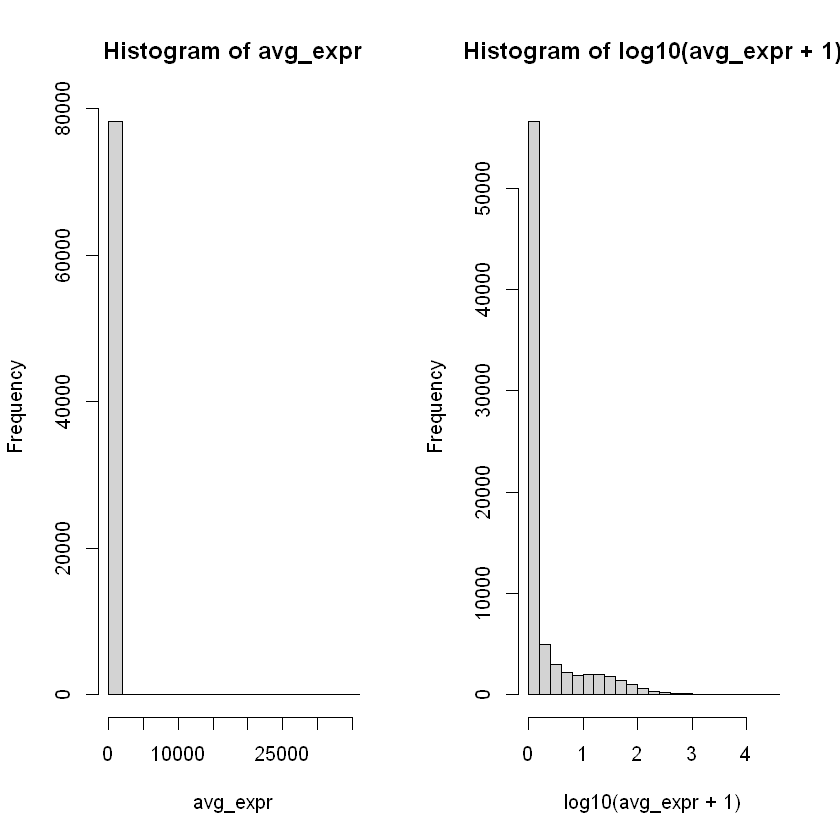

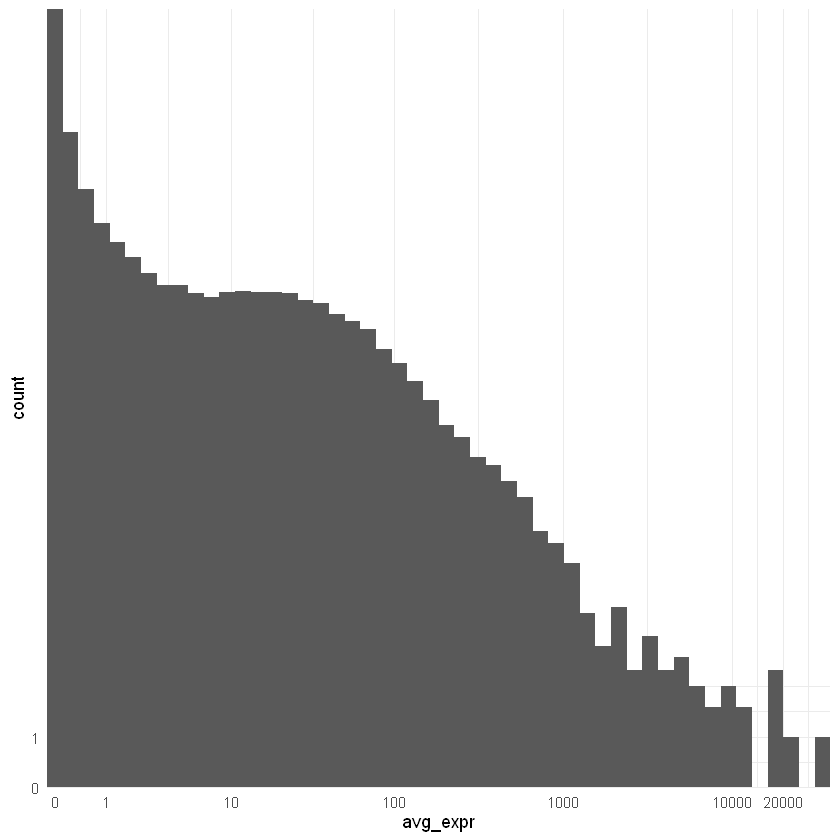

In [6]:
# Checking average expression levels
avg_expr <- rowMeans(expr)

layout(matrix(1:2, nrow=1))
hist(avg_expr)
hist(log10(avg_expr + 1))


library(ggplot2)

ggplot(data.frame(avg_expr), aes(x=avg_expr)) +
  geom_histogram(bins = 50) +
  scale_x_continuous(breaks = c(0,1,10,100,1000,10000,20000), trans="log1p", expand=c(0,0)) +
  scale_y_continuous(breaks = c(0,1), expand=c(0,0), trans="log1p") +
  theme_minimal()

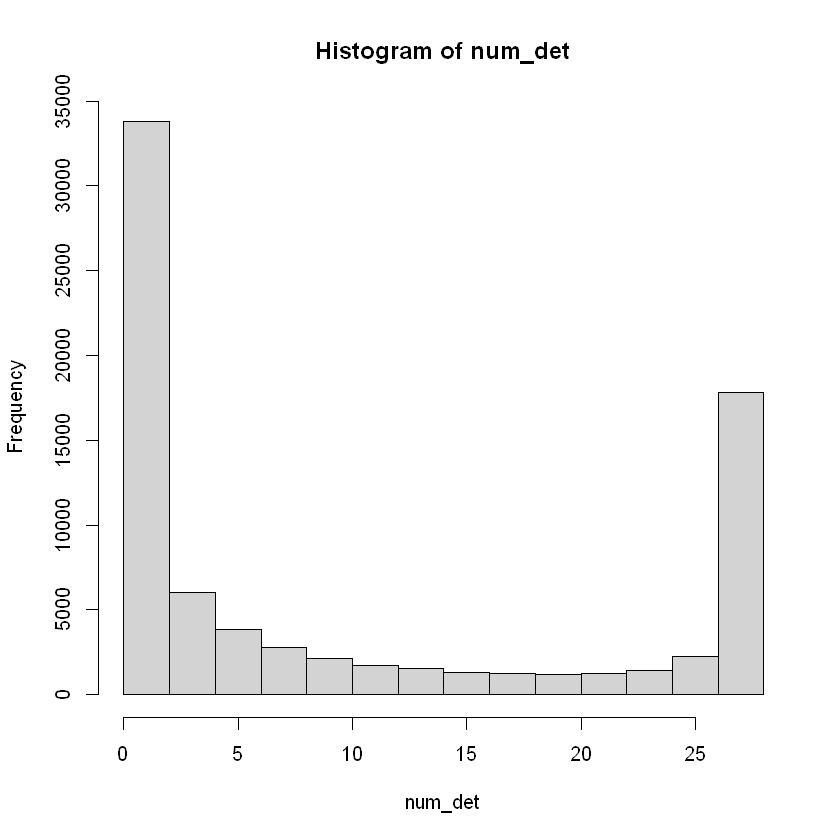

In [7]:
# Checking in how many samples each gene is detected
num_det <- rowSums(expr > 0)
hist(num_det)

# Using the threshold of 1) being detected in at least half of the samples, or 2) average TPM>=1, to define whether a gene is expressed or not.
expressed <- rowMeans(expr > 0) >= 0.5 | rowMeans(expr) >= 1

## Removing genes that do not meet the threshold from the data set
#expr <- expr[which(expressed),]
#meta_genes <- meta_genes[which(expressed),]

# (Alternative) Adding a column at the gene metadata information table to mark whether it is expressed
meta_genes$expressed <- expressed

## Correlations between samples
PCC is a great and fast estimate of linear relationships when the variables are normal distributed, while SCC is non-parametric and therefore more robust to the data distribution.

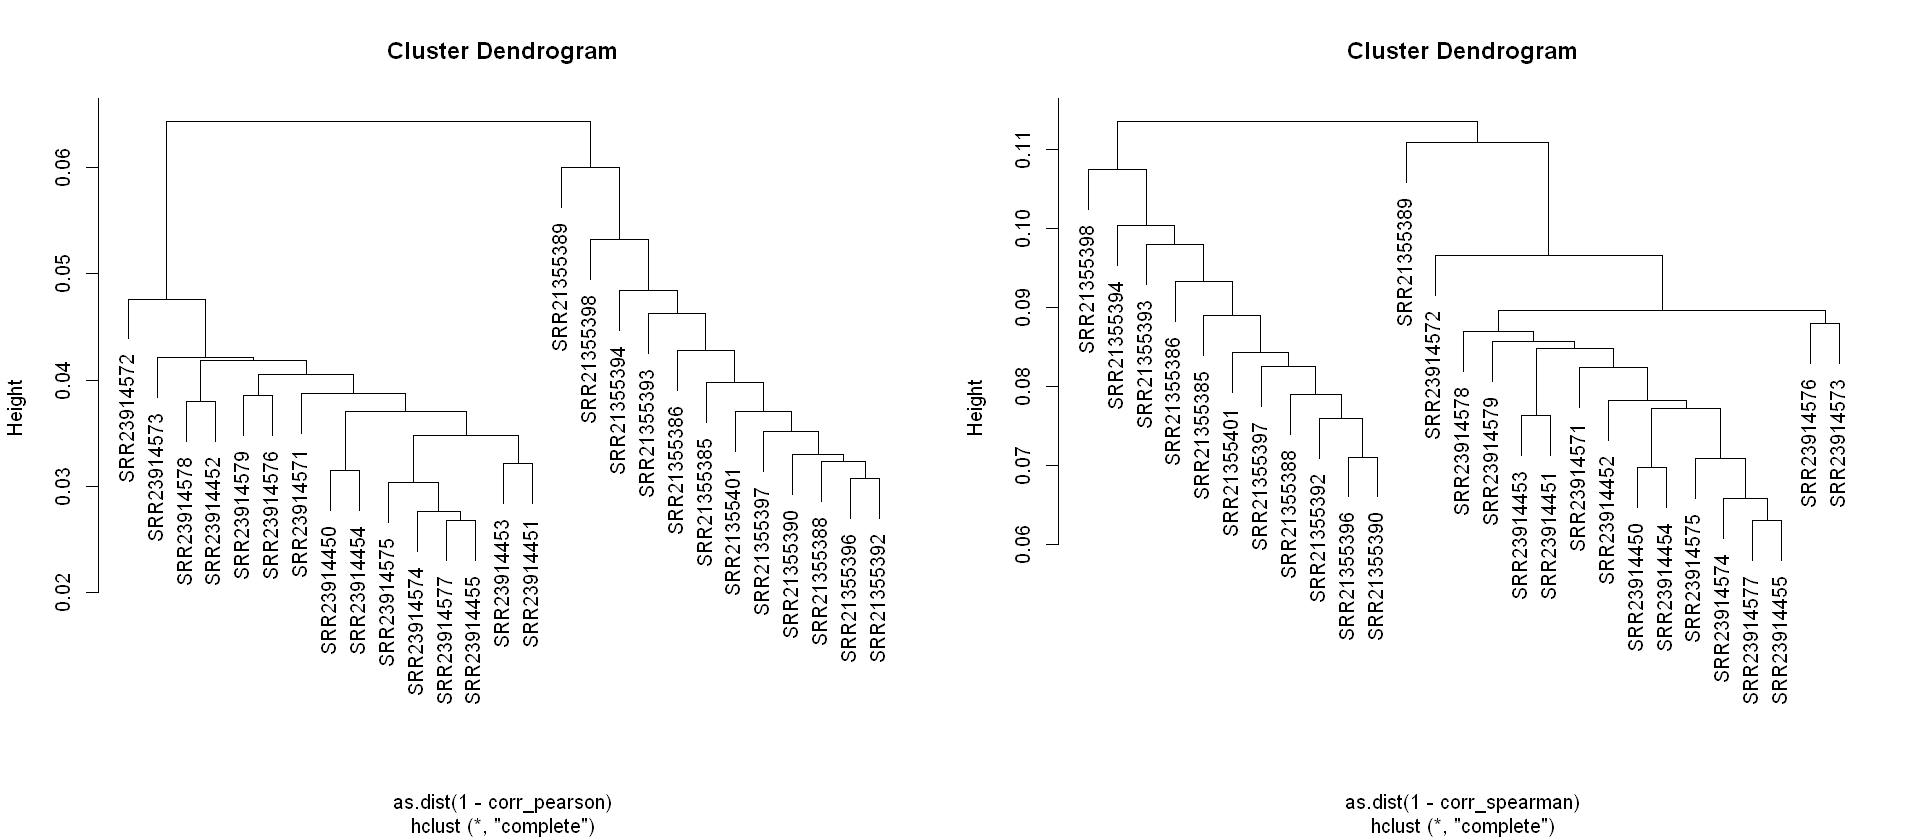

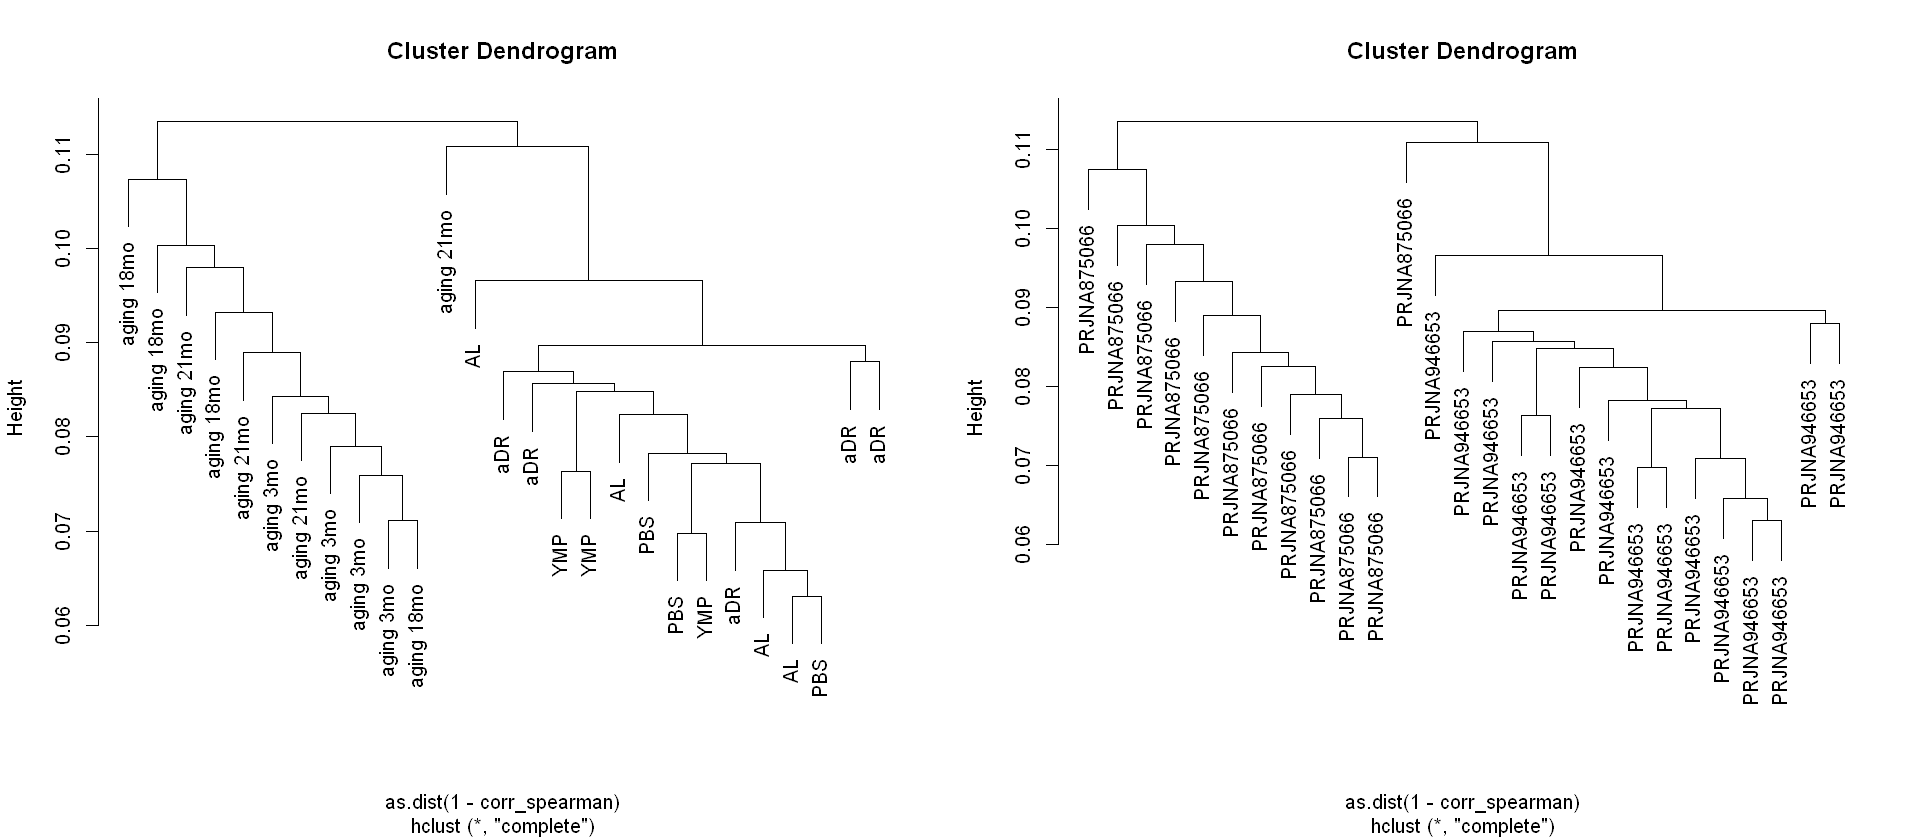

In [8]:
# Calculating PCC and SCC between samples
options(repr.plot.width = 16, repr.plot.height = 7)

corr_pearson <- cor(log1p(expr[meta_genes$expressed,]))
corr_spearman <- cor(expr[meta_genes$expressed,], method = "spearman")

# Apply hierarchical clustering to the samples, given the correlation coefficients as similarities
hcl_pearson <- hclust(as.dist(1 - corr_pearson))
hcl_spearman <- hclust(as.dist(1 - corr_spearman))

layout(matrix(1:2,nrow=1))
plot(hcl_pearson)
plot(hcl_spearman)



# Plotting the meta data labels instead of the accessions
layout(matrix(1:2,nrow=1))
plot(hcl_spearman, labels = meta$group)
plot(hcl_spearman, labels = meta$dataset)

Result Description: This clustering shows that the data clusters into datasets, meaning there is a strong batch effect. Therefore clustering and PCA should be done per dataset. 

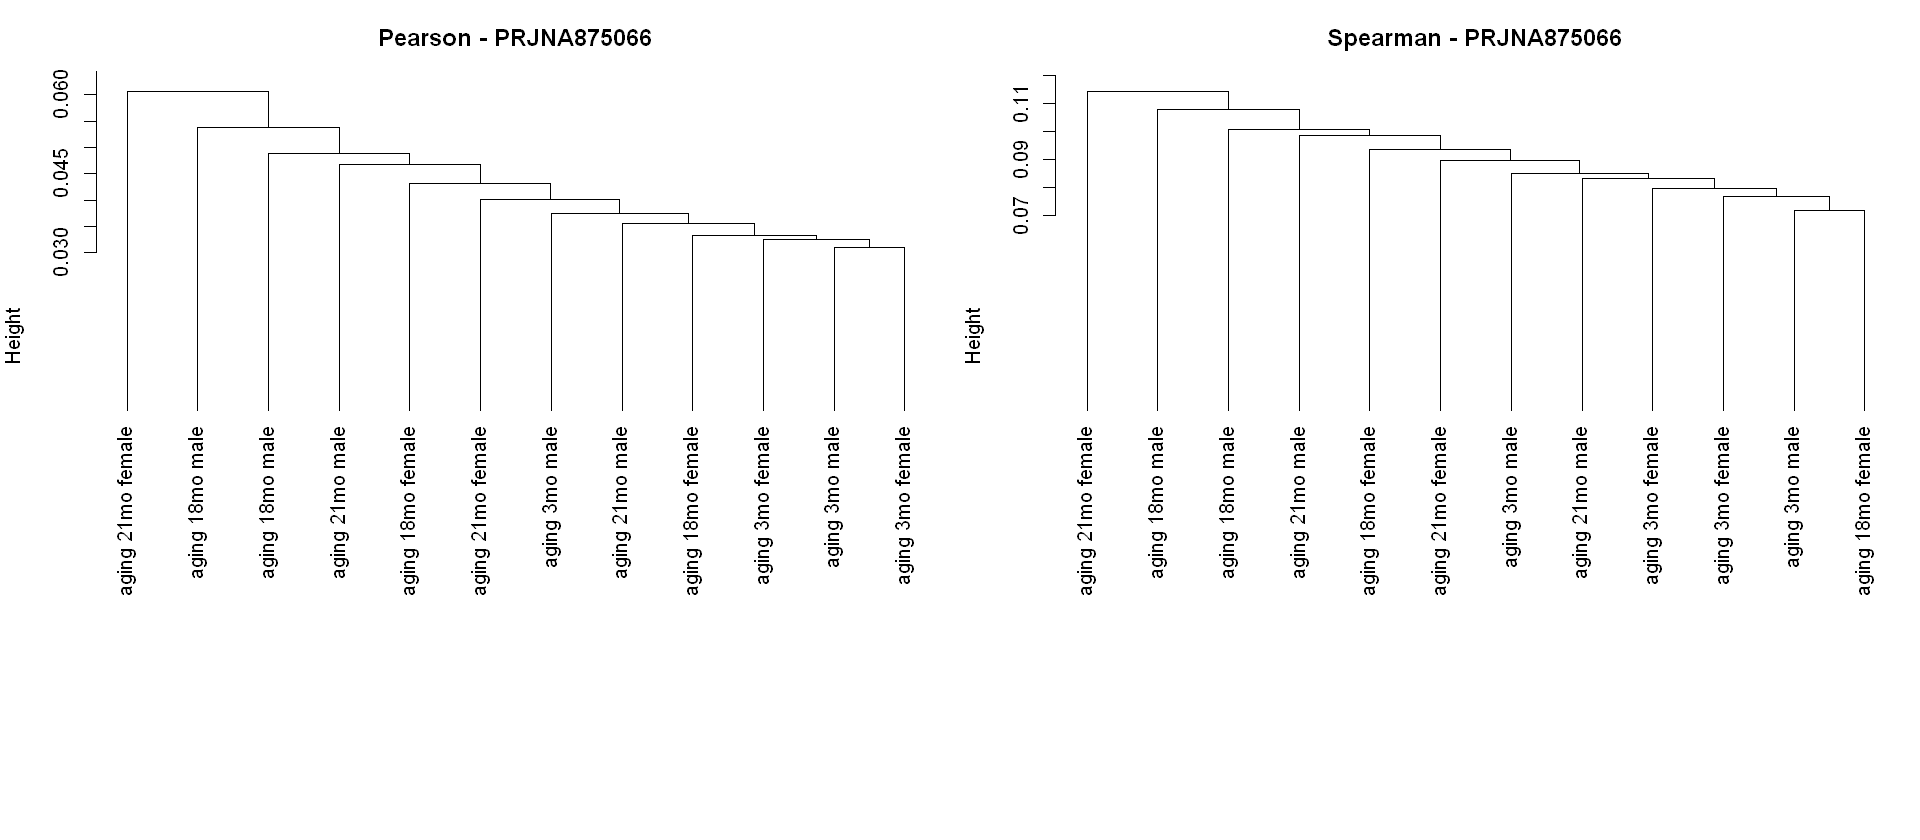

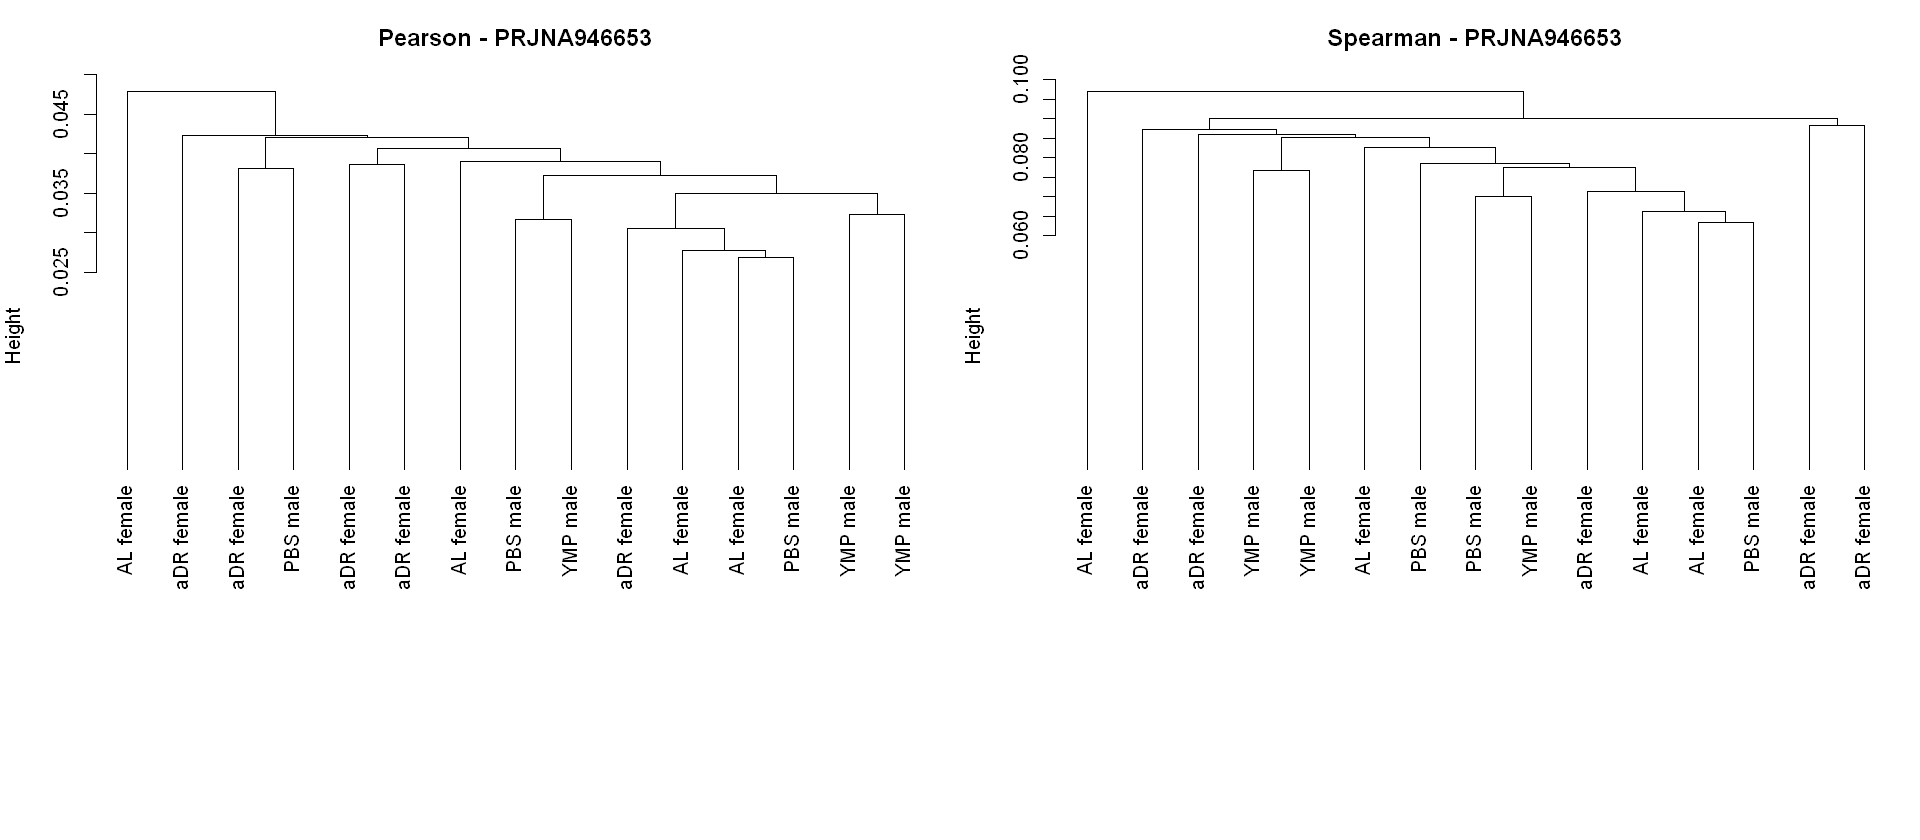

In [9]:
# Clustering within each dataset separately
options(repr.plot.width = 16, repr.plot.height = 7)

for (ds in unique(meta$dataset)) {
  # Samples of this dataset
  s <- meta$SRR[meta$dataset == ds]
  x <- expr[meta_genes$expressed, s]
  x <- x[apply(x, 1, var) > 0, ]   # dropping genes that are constant in this dataset

  # Calculating PCC and SCC between samples
  corr_pearson_ds  <- cor(log1p(x))
  corr_spearman_ds <- cor(x, method = "spearman")

  # Hierarchical clustering
  hcl_pearson_ds  <- hclust(as.dist(1 - corr_pearson_ds))
  hcl_spearman_ds <- hclust(as.dist(1 - corr_spearman_ds))

  # Labels: group and sex of each sample
  labs <- paste(meta$group, meta$sex)[match(s, meta$SRR)]

  layout(matrix(1:2, nrow = 1))
  par(mar = c(10, 4, 3, 1))
  plot(hcl_pearson_ds,  labels = labs, hang = -1, main = paste("Pearson -", ds),  xlab = "", sub = "")
  plot(hcl_spearman_ds, labels = labs, hang = -1, main = paste("Spearman -", ds), xlab = "", sub = "")
}


Result Description: Neither Pearson nor Spearman clusters age groups/interventions consistently within their respective datasets.

Another way to check similarities between samples is to use dimension reduction techniques.
--> Principal component analysis (PCA)

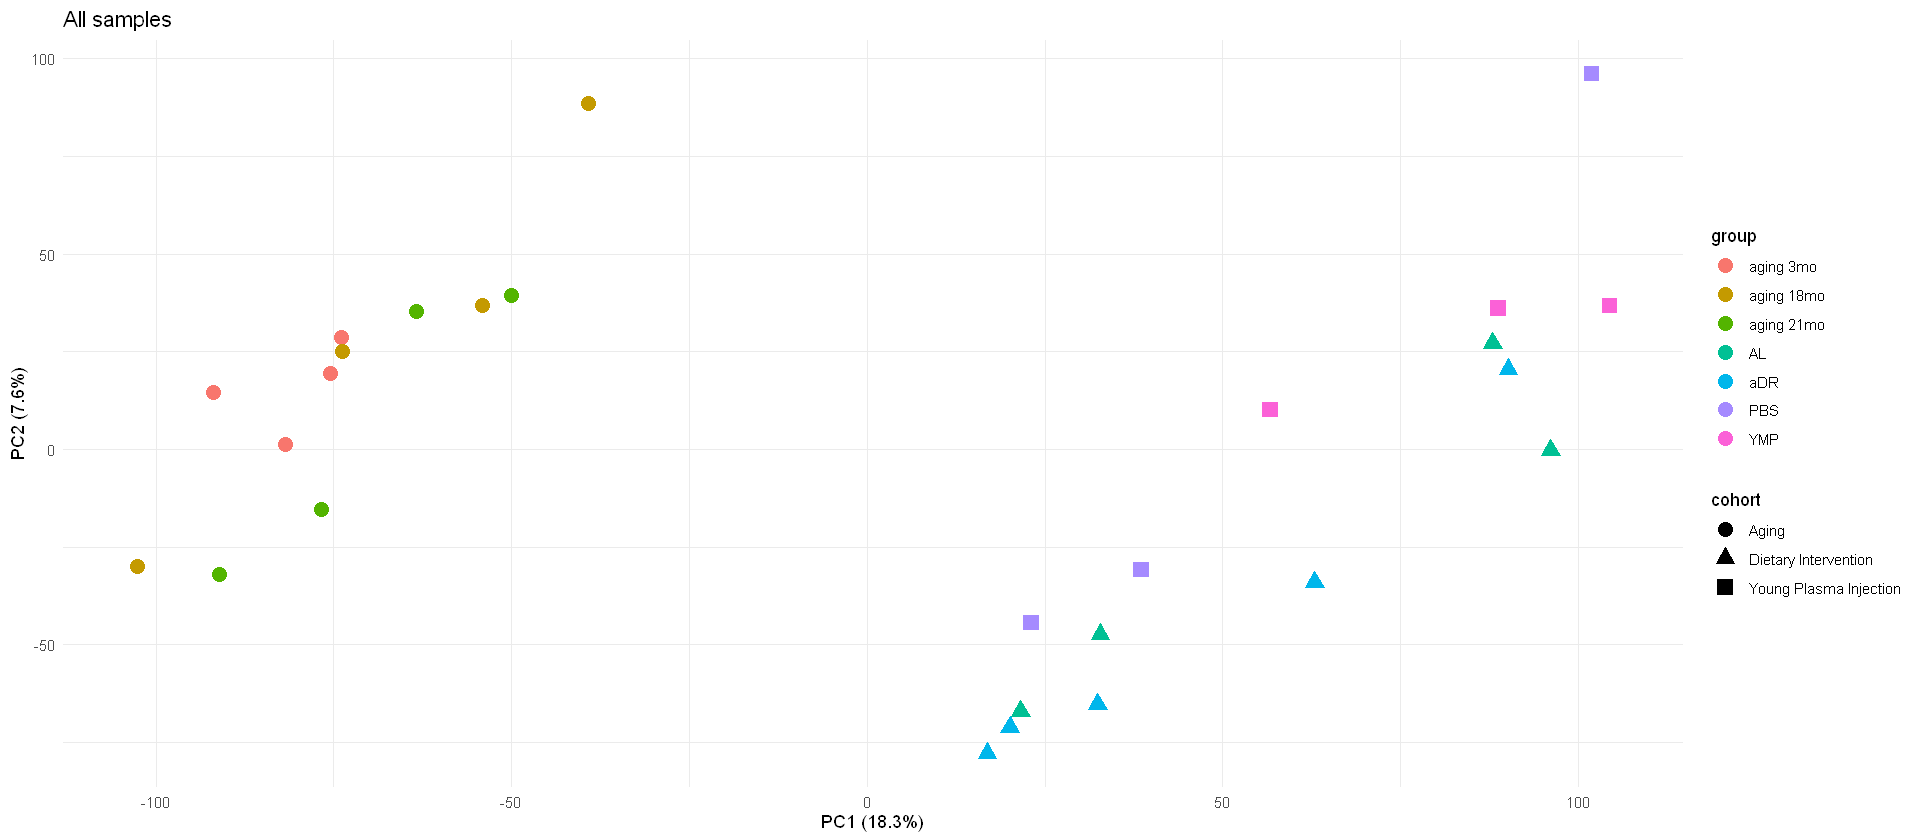

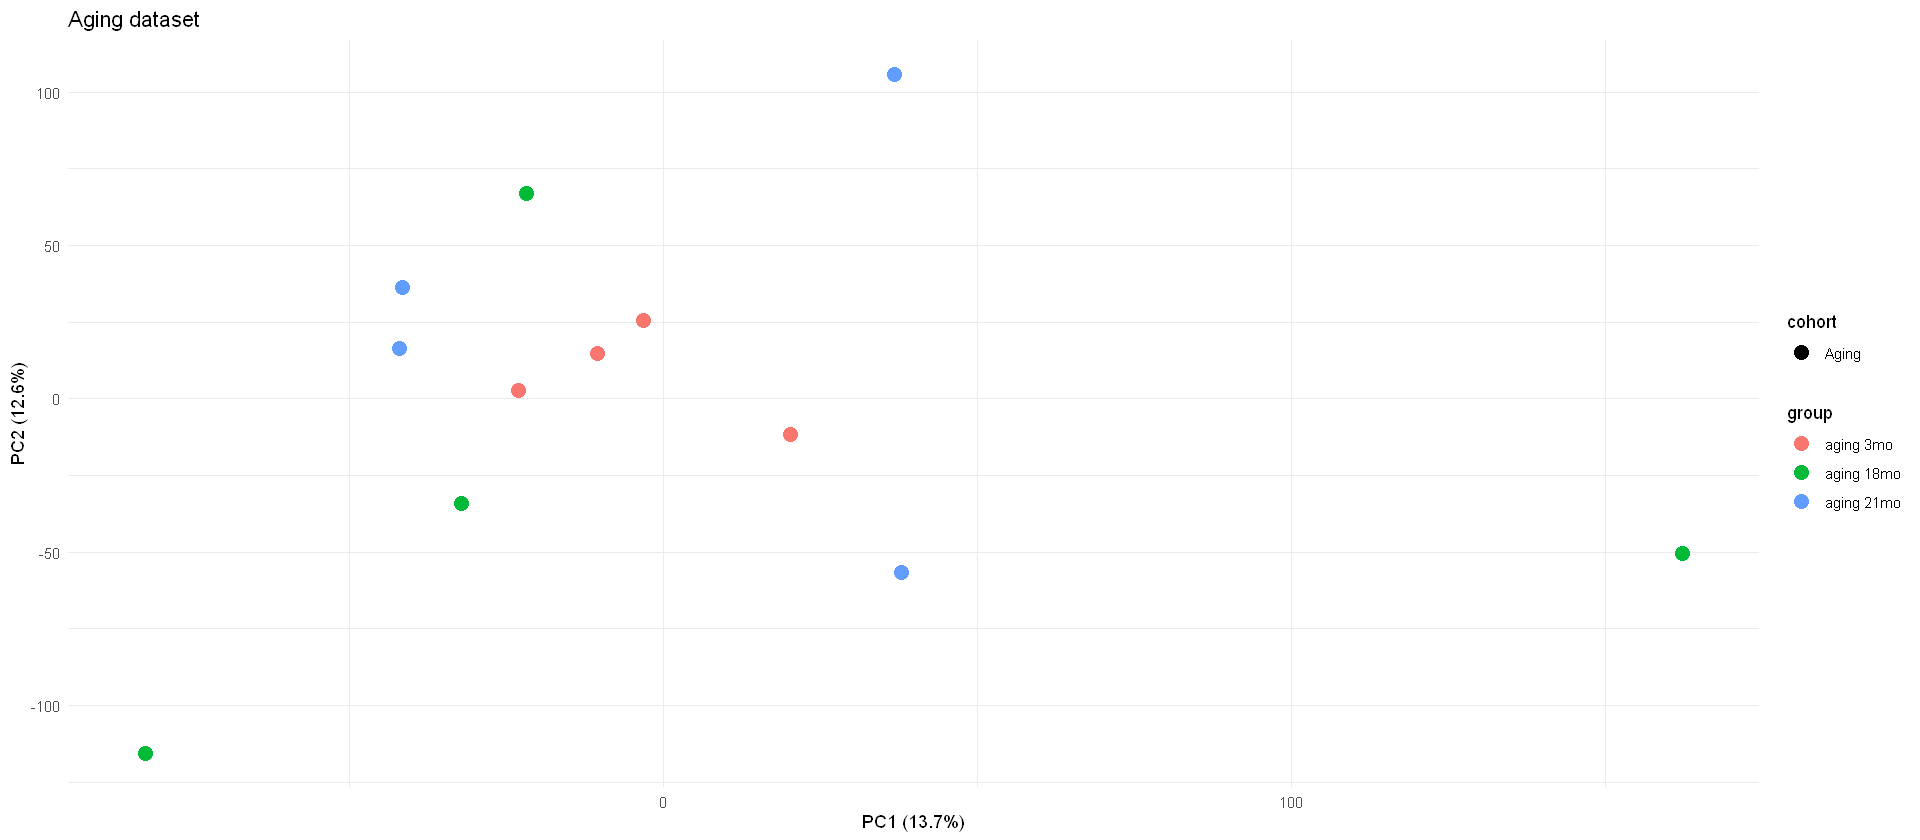

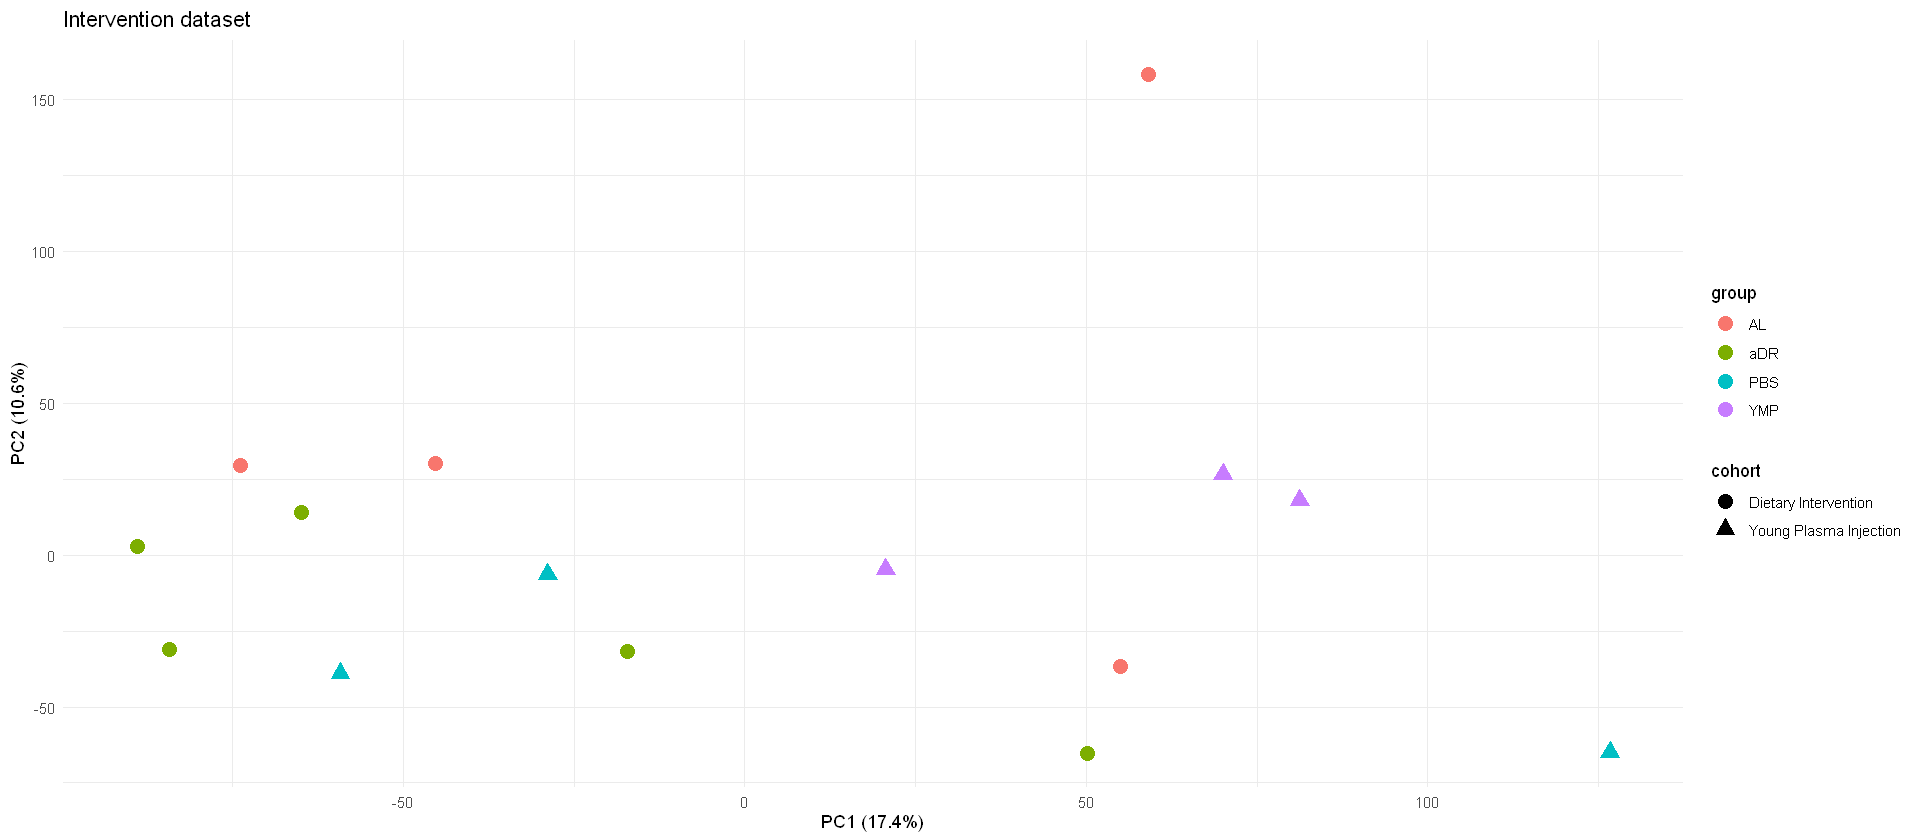

In [10]:
# Function: PCA on a subset of samples
plot_pca <- function(samples, title) {
  x <- log1p(t(expr[meta_genes$expressed, samples]))
  x <- x[, apply(x, 2, var) > 0]      # remove genes that are constant in this subset
  pca <- prcomp(x, center = TRUE, scale. = TRUE)
  var_expl <- round(100 * pca$sdev^2 / sum(pca$sdev^2), 1)
  ggplot(data.frame(pca$x, meta[match(samples, meta$SRR), ])) +
    geom_point(aes(x = PC1, y = PC2, color = group, shape = cohort), size = 4) +
    labs(title = title,
         x = paste0("PC1 (", var_expl[1], "%)"),
         y = paste0("PC2 (", var_expl[2], "%)")) +
    theme_minimal()
}

plot_pca(meta$SRR, "All samples")
plot_pca(meta$SRR[meta$dataset == "PRJNA875066"], "Aging dataset")
plot_pca(meta$SRR[meta$dataset == "PRJNA946653"], "Intervention dataset")


Result Description: PC1 seperates aging from intervention. 
PC1 does not seperate different age groups, nor does it seperate different interventions.

## Differential Expression (per Dataset)

In [11]:
library(DESeq2)

# Function: DESeq2 on a subset of samples, comparing "treat" vs "ctrl"
run_de <- function(samples, condition, design = ~ condition) {
  cd <- meta[match(samples, meta$SRR), ]
  cd$condition <- condition
  cts <- round(counts[, samples])        # RSEM expected counts are not integers
  cts <- cts[rowSums(cts >= 10) >= 3, ]  # keep genes with at least 10 reads in at least 3 samples
  dds <- DESeqDataSetFromMatrix(cts, colData = cd, design = design)
  dds <- DESeq(dds)  #DESeq() does three things: Normalisation: corrects for the fact that some samples were sequenced more deeply than others ("size factors"). Dispersion estimation: works out how much each gene varies naturally between replicates. With only 3–5 mice per group, the estimate for a single gene would be very unreliable, so DESeq2 borrows information across all genes. Statistical test: fits a model for every gene and tests whether the condition has an effect (Wald test).
  res <- as.data.frame(results(dds, contrast = c("condition", "treat", "ctrl")))
  res$gene_id <- rownames(res)
  res$symbol  <- meta_genes$symbol[match(res$gene_id, meta_genes$gene_id)]
  res[order(res$padj), ]
}

# Aging: each age group separately against 3 months (no pooling), correcting for sex
s_age <- meta$SRR[meta$cohort == "Aging"]
cd_age <- meta[match(s_age, meta$SRR), ]
cd_age$age <- factor(paste0("m", cd_age$age_months), levels = c("m3", "m18", "m21"))

cts_age <- round(counts[, s_age])
cts_age <- cts_age[rowSums(cts_age >= 10) >= 3, ]

dds_age <- DESeqDataSetFromMatrix(cts_age, colData = cd_age, design = ~ sex + age)
dds_age <- DESeq(dds_age)

# Function: extract one contrast and add gene symbols
get_res <- function(dds, contrast) {
  res <- as.data.frame(results(dds, contrast = contrast))
  res$gene_id <- rownames(res)
  res$symbol  <- meta_genes$symbol[match(res$gene_id, meta_genes$gene_id)]
  res[order(res$padj), ]
}

de_age18    <- get_res(dds_age, c("age", "m18", "m3"))   # 18 mo vs 3 mo
de_age21    <- get_res(dds_age, c("age", "m21", "m3"))   # 21 mo vs 3 mo
de_age21v18 <- get_res(dds_age, c("age", "m21", "m18"))  # 21 mo vs 18 mo

# Dietary restriction: aDR vs AL
s_diet <- meta$SRR[meta$group %in% c("AL", "aDR")]
cond   <- factor(ifelse(meta$group[match(s_diet, meta$SRR)] == "aDR", "treat", "ctrl"),
                 levels = c("ctrl", "treat"))
de_diet <- run_de(s_diet, cond)

# Young plasma: YMP vs PBS
s_plasma <- meta$SRR[meta$group %in% c("PBS", "YMP")]
cond     <- factor(ifelse(meta$group[match(s_plasma, meta$SRR)] == "YMP", "treat", "ctrl"),
                   levels = c("ctrl", "treat"))
de_plasma <- run_de(s_plasma, cond)

# Number of significant genes per comparison
sapply(list(age18 = de_age18, age21 = de_age21, age21v18 = de_age21v18,
            diet = de_diet, plasma = de_plasma),
       function(r) sum(r$padj < 0.05, na.rm = TRUE))

head(de_age21[, c("symbol", "log2FoldChange", "padj")], 20)


converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
"some variables in design formula are characters, converting to factors"
estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

converting counts to integer mode

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

converting counts to integer mode

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



   age18    age21 age21v18     diet   plasma 
     118      274       26      174       37 

                      symbol  log2FoldChange padj        
ENSMUSG00000009216.9  Fam163b  1.8894146     1.789941e-32
ENSMUSG00000073418.6  C4b      1.9891870     4.658295e-23
ENSMUSG00000079293.13 Clec7a   3.8077272     6.128725e-14
ENSMUSG00000038642.12 Ctss     1.0297950     1.513834e-11
ENSMUSG00000103897.3  Pcdhga8  0.8635765     1.708057e-10
ENSMUSG00000035274.15 Tpbg     1.3904187     8.093694e-10
ENSMUSG00000036905.10 C1qb     0.9995966     8.093694e-10
ENSMUSG00000073409.14 H2-Q6    3.2415904     1.693840e-09
ENSMUSG00000018774.15 Cd68     1.7081252     4.572880e-09
ENSMUSG00000050335.19 Lgals3   1.9263434     4.572880e-09
ENSMUSG00000020932.16 Gfap     0.7629946     6.682636e-09
ENSMUSG00000007891.18 Ctsd     0.5104582     1.056424e-08
ENSMUSG00000072235.8  Tuba1a  -0.3100720     1.141273e-08
ENSMUSG00000060550.19 H2-Q7    3.1647362     1.281757e-08
ENSMUSG00000016256.12 Ctsz     0.6531386     2.999411e-08
ENSMUSG00000112148.3  Lilrb4a  4.8460945     5.021408e-08
ENSMUSG0000002

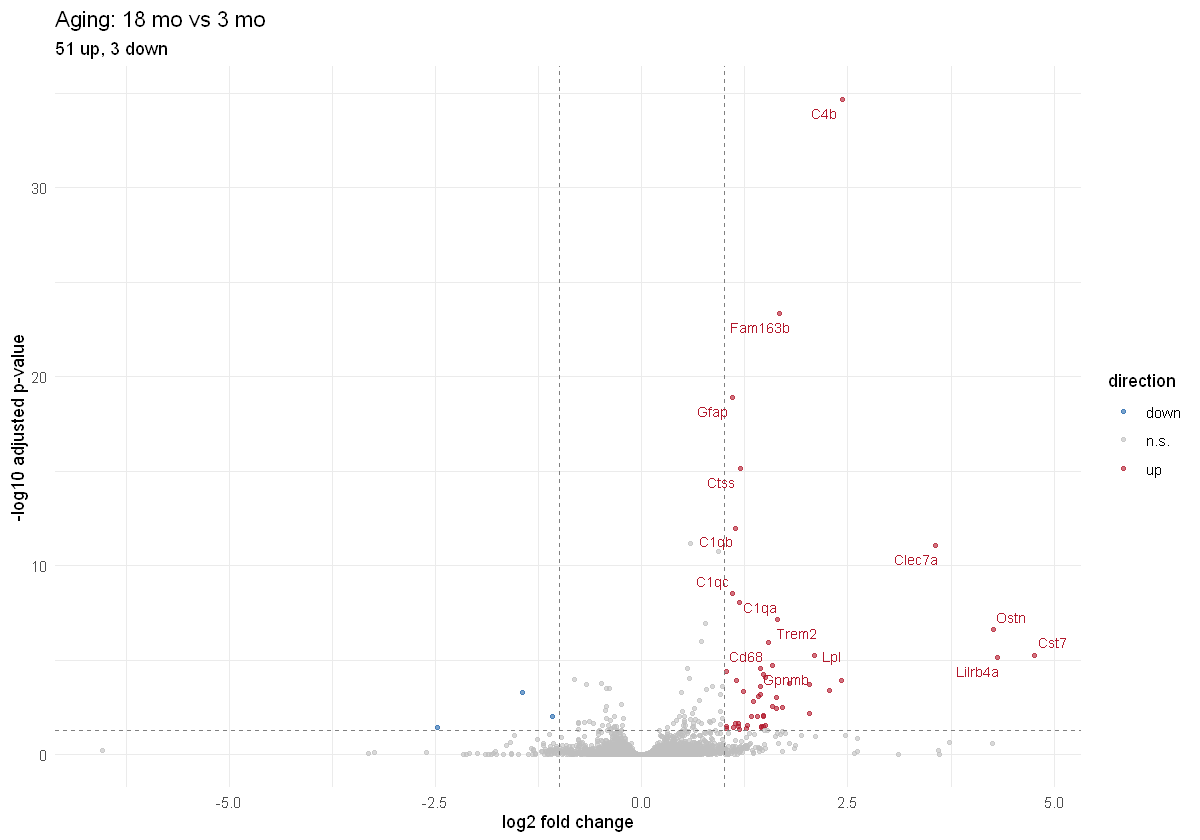

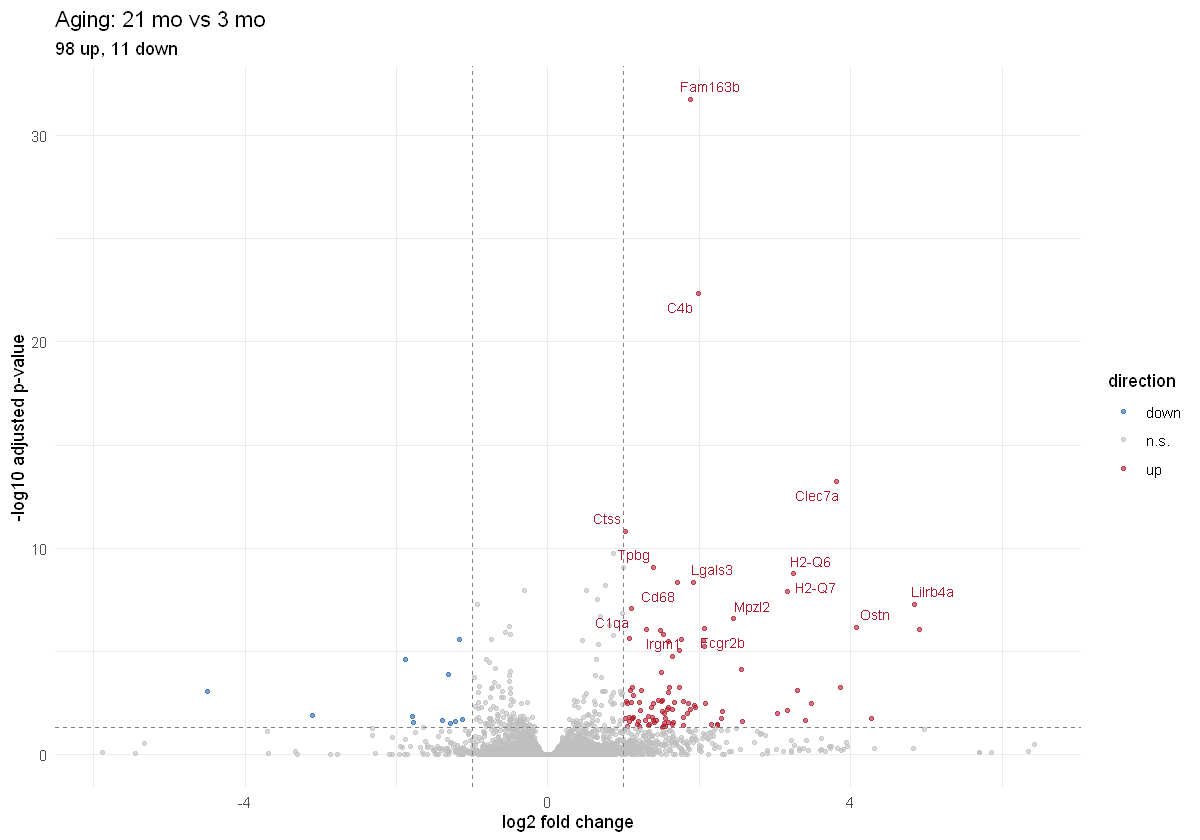

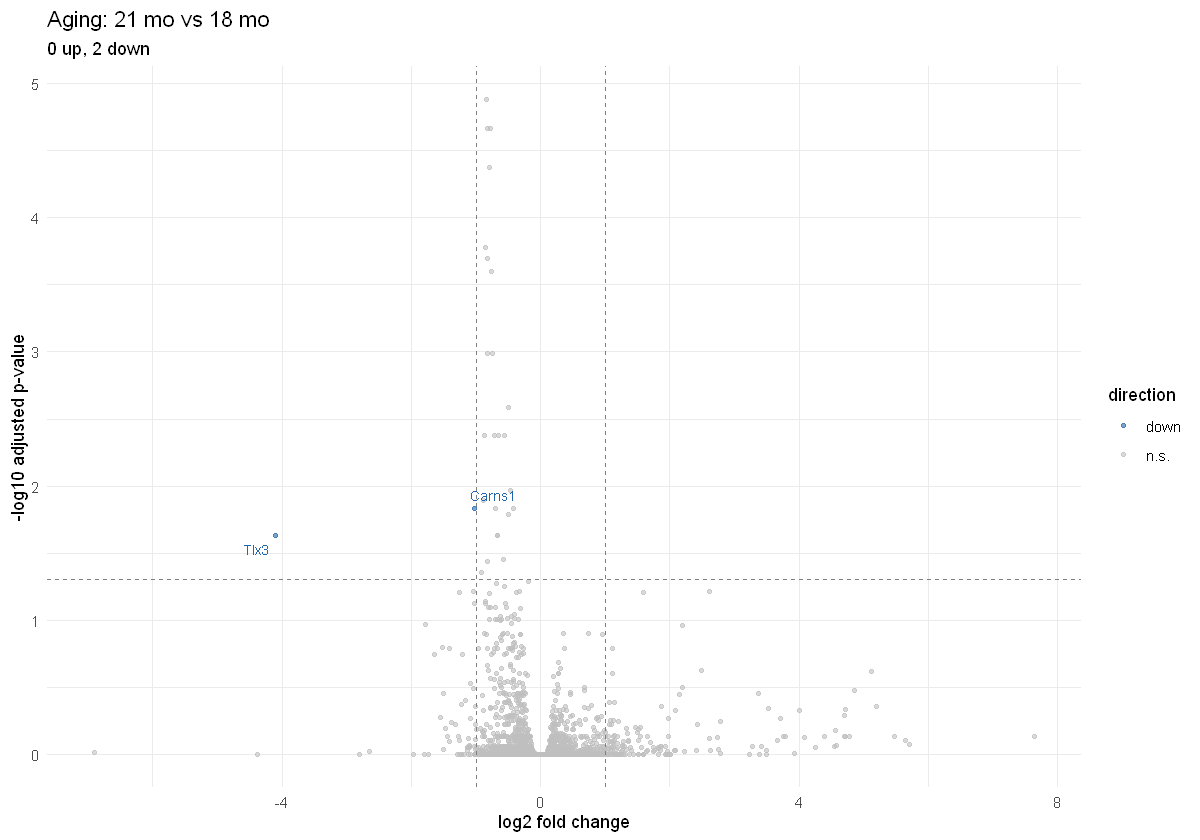

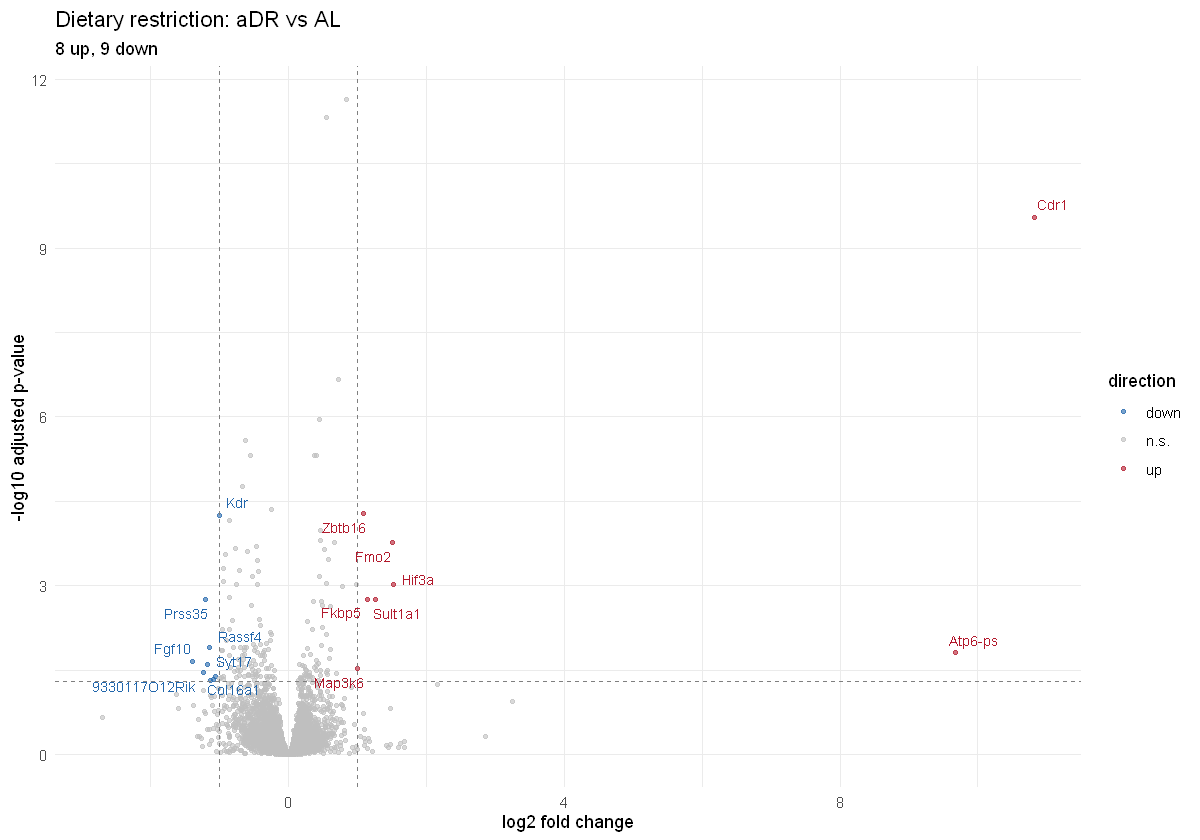

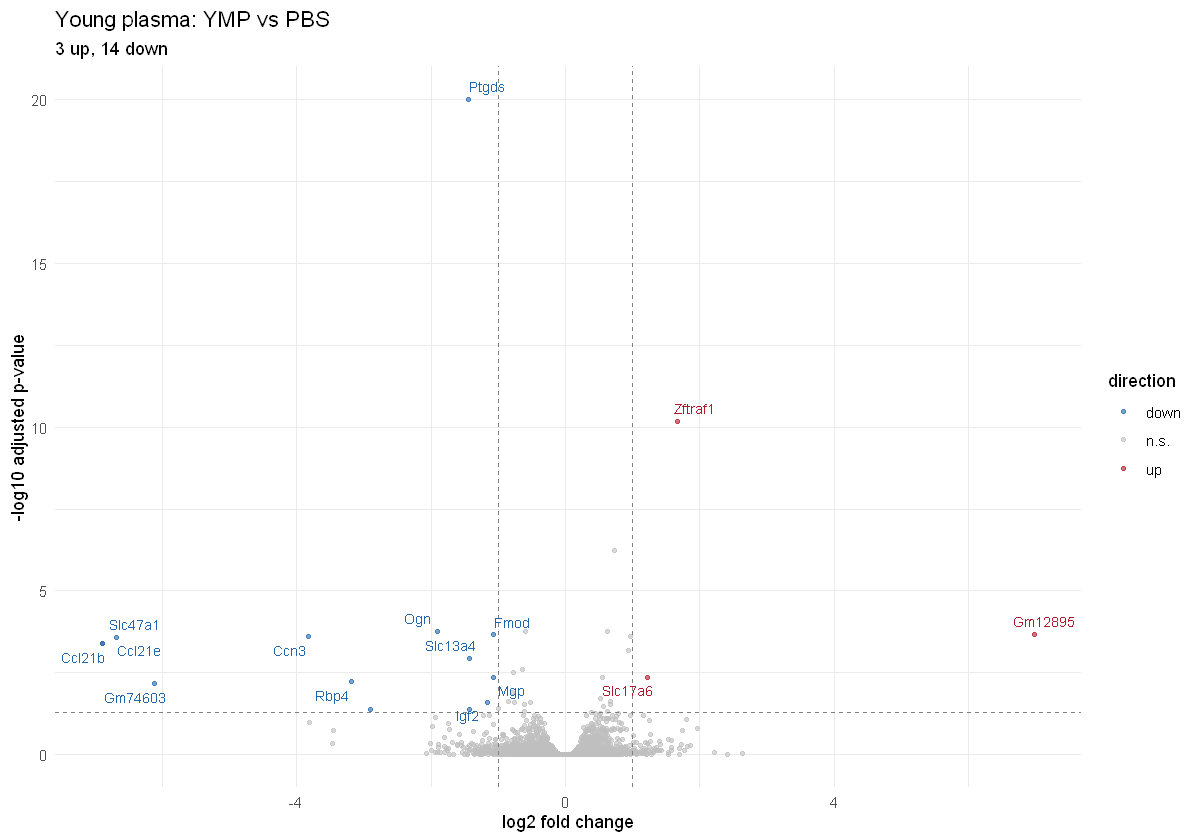

In [12]:
library(ggrepel)
options(repr.plot.width = 10, repr.plot.height = 7)

# Function: volcano plot of one DE result table
plot_volcano <- function(res, title, padj_cut = 0.05, lfc_cut = 1, n_labels = 15) {
  res <- res[!is.na(res$padj), ]
  res$direction <- "n.s."
  res$direction[res$padj < padj_cut & res$log2FoldChange >  lfc_cut] <- "up"
  res$direction[res$padj < padj_cut & res$log2FoldChange < -lfc_cut] <- "down"
  top <- head(res[res$direction != "n.s.", ], n_labels)   # res is sorted by padj

  ggplot(res, aes(x = log2FoldChange, y = -log10(padj), color = direction)) +
    geom_point(size = 1, alpha = 0.6) +
    geom_vline(xintercept = c(-lfc_cut, lfc_cut), linetype = "dashed", color = "grey50") +
    geom_hline(yintercept = -log10(padj_cut), linetype = "dashed", color = "grey50") +
    geom_text_repel(data = top, aes(label = symbol), size = 3, max.overlaps = 20, show.legend = FALSE) +
    scale_color_manual(values = c(down = "#2166ac", n.s. = "grey75", up = "#b2182b")) +
    labs(title = title,
         subtitle = paste0(sum(res$direction == "up"), " up, ",
                           sum(res$direction == "down"), " down"),
         x = "log2 fold change", y = "-log10 adjusted p-value") +
    theme_minimal()
}

plot_volcano(de_age18,    "Aging: 18 mo vs 3 mo")
plot_volcano(de_age21,    "Aging: 21 mo vs 3 mo")
plot_volcano(de_age21v18, "Aging: 21 mo vs 18 mo")
plot_volcano(de_diet,     "Dietary restriction: aDR vs AL")
plot_volcano(de_plasma,   "Young plasma: YMP vs PBS")


The horizontal dashed line is padj = 0.05.
The vertical dashed lines mark log2FC = ±1, i.e. a 2-fold change. Genes are only coloured if they pass both thresholds.
The 15 most significant coloured genes are labelled.



---------------------
gplots 3.3.0 loaded:
  * Use citation('gplots') for citation info.
  * Homepage: https://talgalili.github.io/gplots/
  * Report issues: https://github.com/talgalili/gplots/issues
  * Ask questions: https://stackoverflow.com/questions/tagged/gplots
  * Suppress this message with: suppressPackageStartupMessages(library(gplots))
---------------------



Attache Paket: 'gplots'


Das folgende Objekt ist maskiert 'package:IRanges':

    space


Das folgende Objekt ist maskiert 'package:S4Vectors':

    space


Das folgende Objekt ist maskiert 'package:stats':

    lowess


Warning message in image.default(z = matrix(z, ncol = 1), col = col, breaks = tmpbreaks, :
"unsortierte 'breaks' werden vor der Nutzung sortiert"
Warning message in image.default(z = matrix(z, ncol = 1), col = col, breaks = tmpbreaks, :
"unsortierte 'breaks' werden vor der Nutzung sortiert"


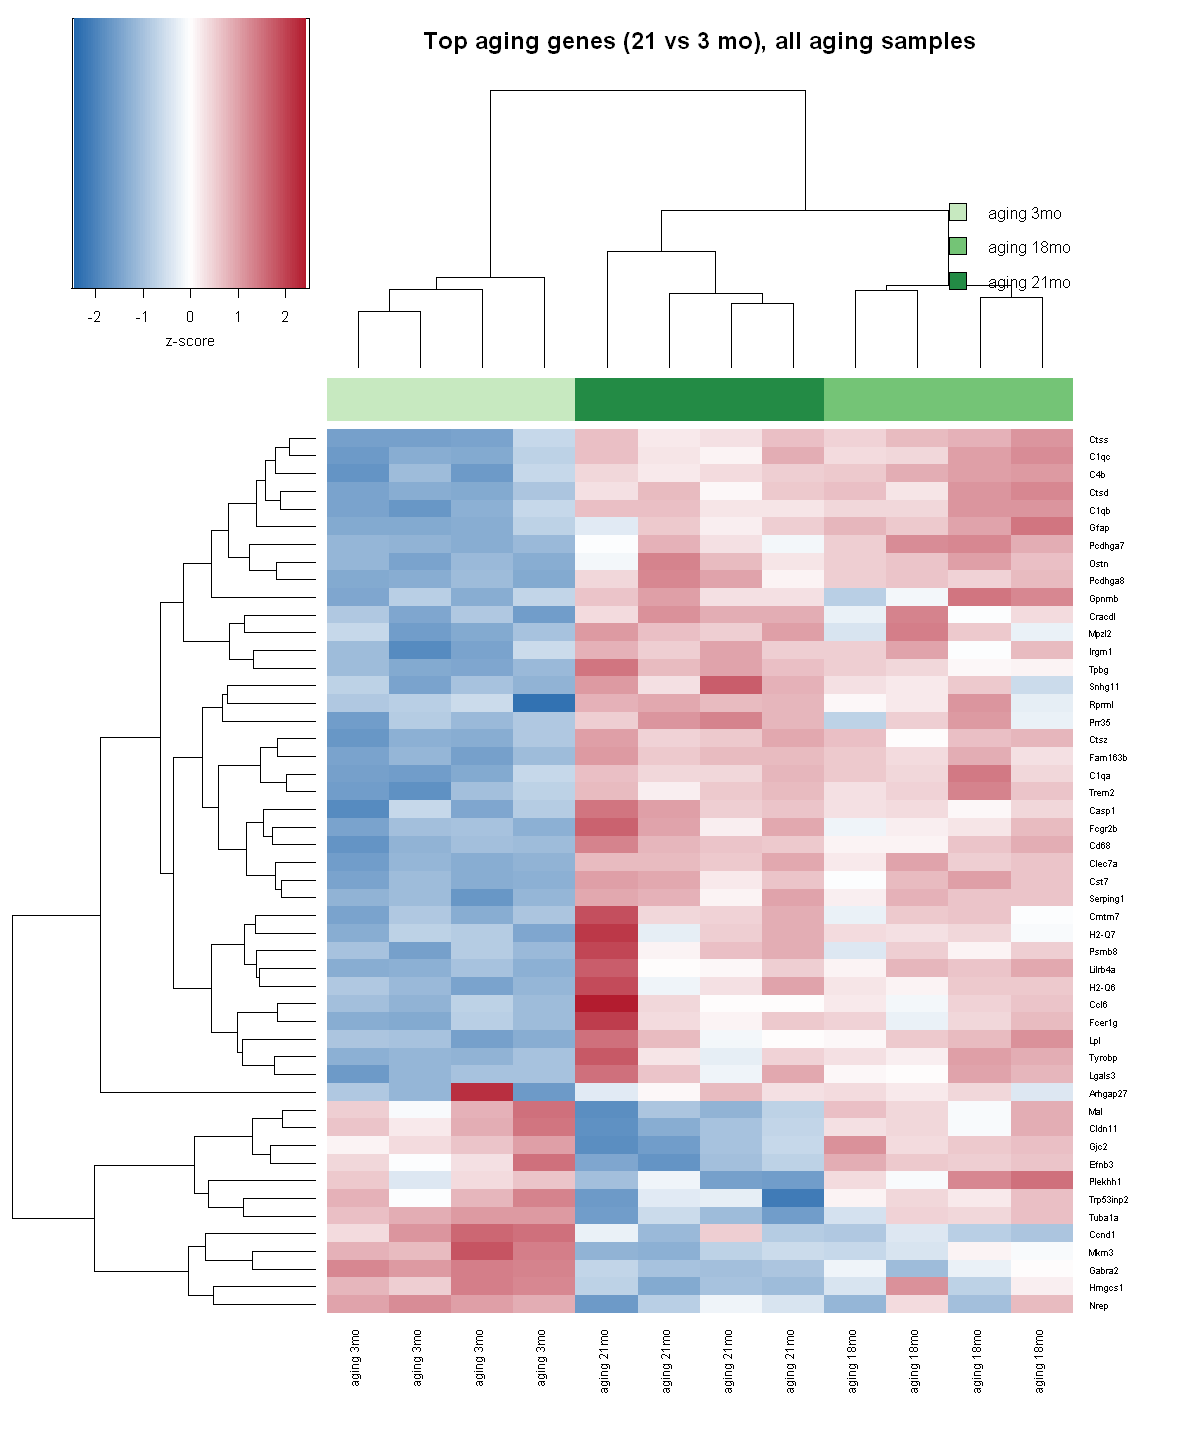

Warning message in image.default(z = matrix(z, ncol = 1), col = col, breaks = tmpbreaks, :
"unsortierte 'breaks' werden vor der Nutzung sortiert"


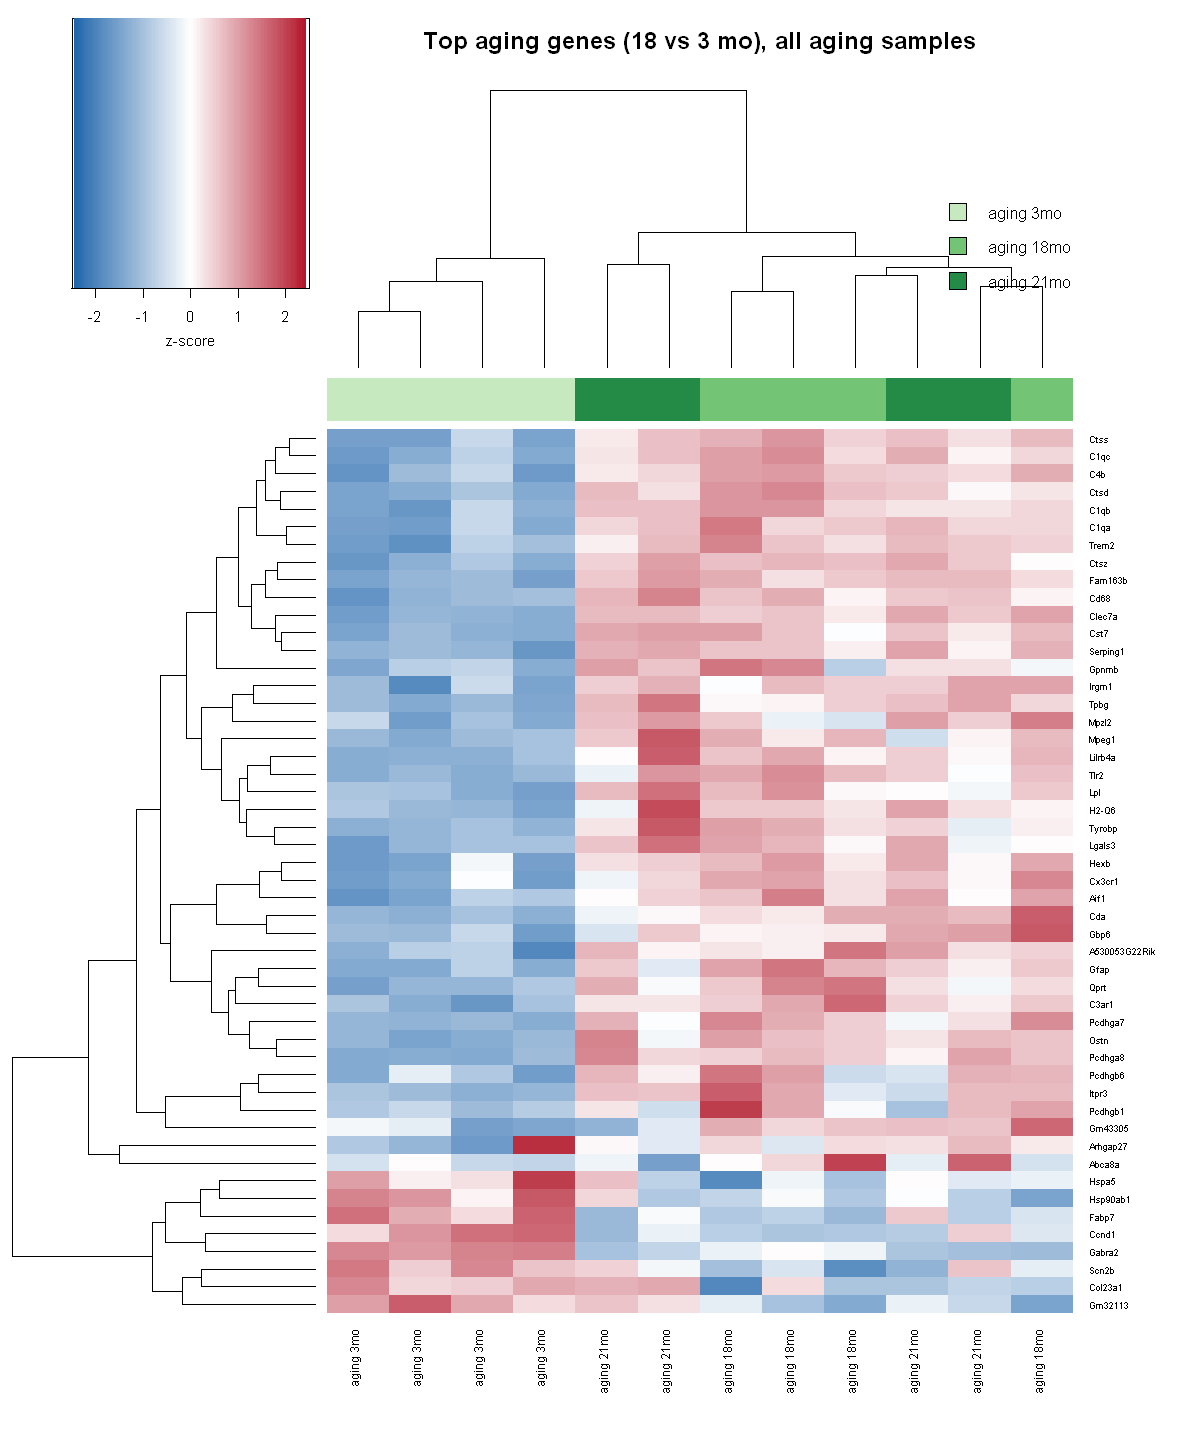

Warning message in image.default(z = matrix(z, ncol = 1), col = col, breaks = tmpbreaks, :
"unsortierte 'breaks' werden vor der Nutzung sortiert"


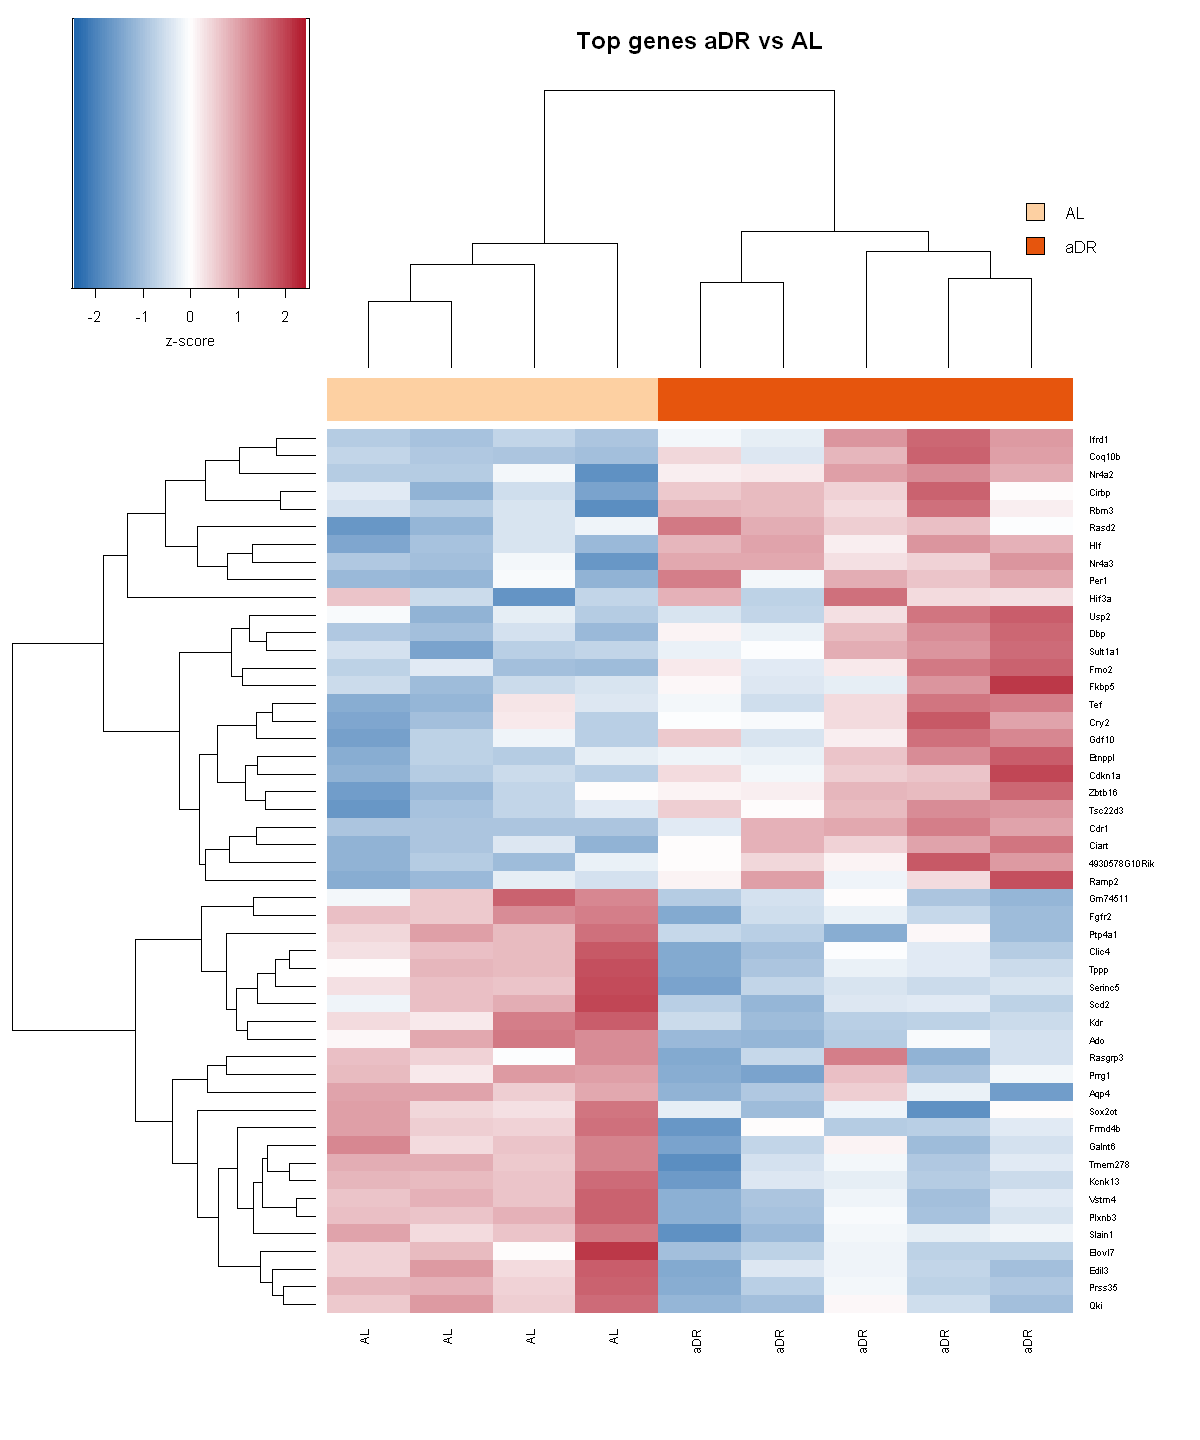

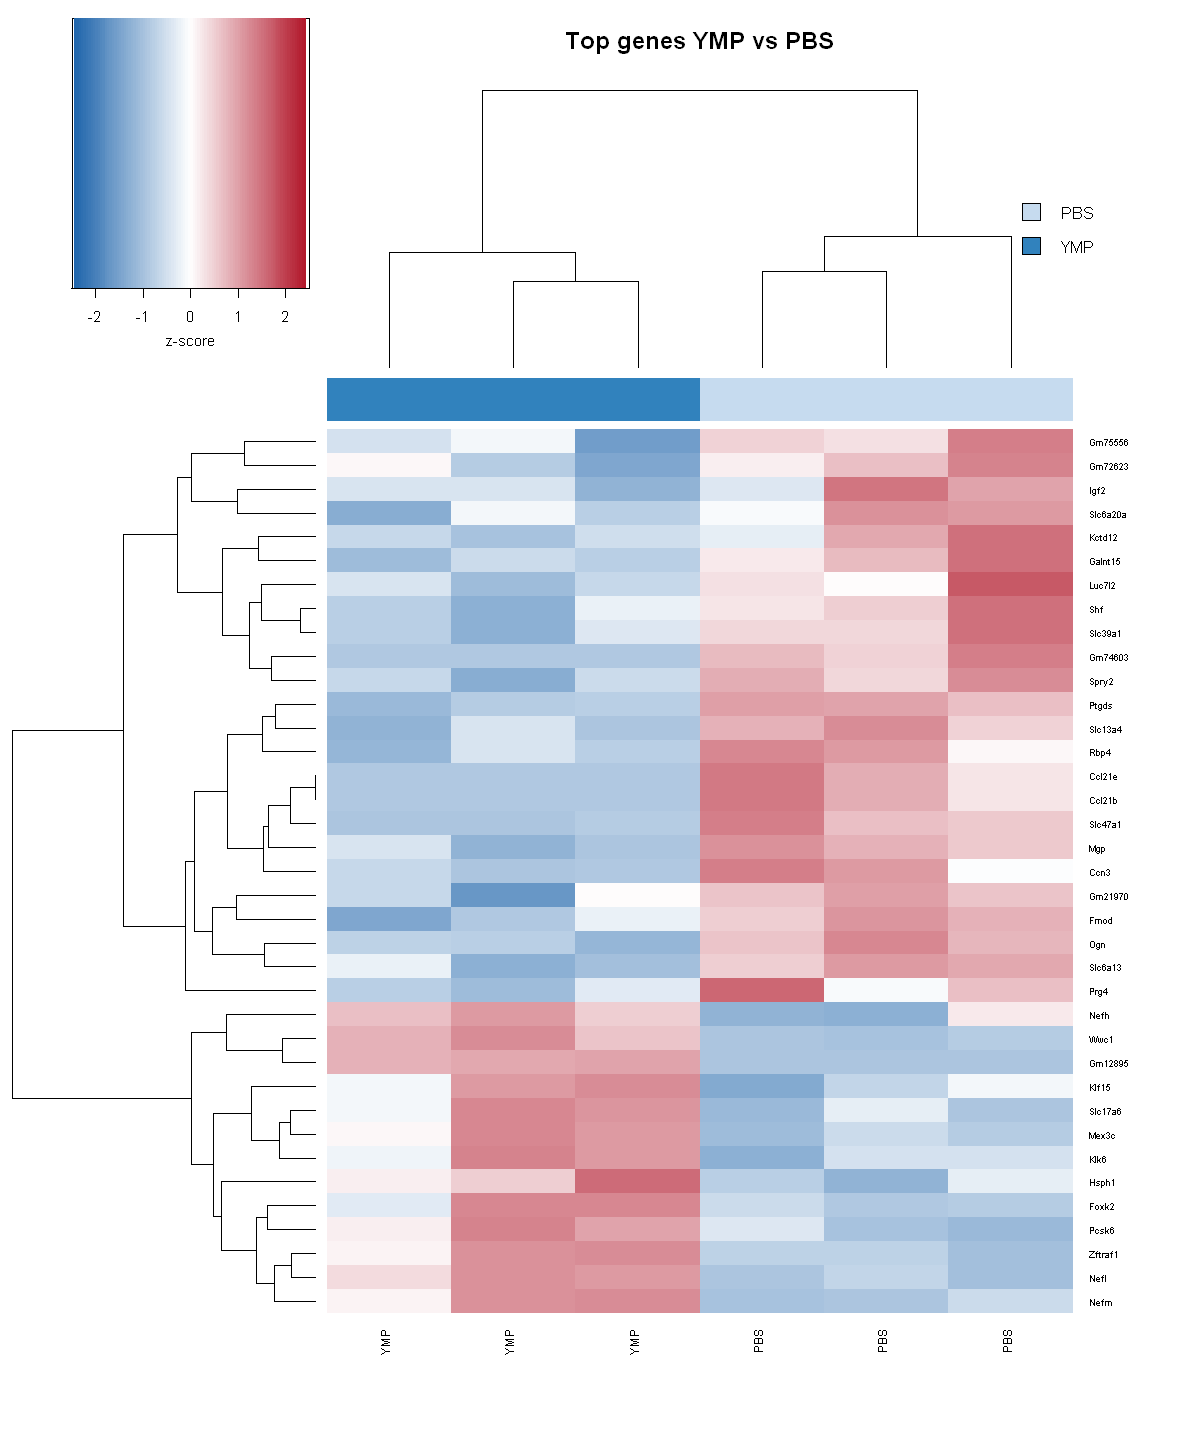

In [13]:
library(gplots)
options(repr.plot.width = 10, repr.plot.height = 12)

# One colour per experimental group (for the bar above the heatmap)
group_cols <- c("aging 3mo" = "#c7e9c0", "aging 18mo" = "#74c476", "aging 21mo" = "#238b45",
                "AL" = "#fdd0a2", "aDR" = "#e6550d",
                "PBS" = "#c6dbef", "YMP" = "#3182bd")

# Function: heatmap of the top n significant genes of one DE result, across the chosen samples
plot_heatmap <- function(res, samples, title, n = 50, padj_cut = 0.05) {
  top <- head(res[!is.na(res$padj) & res$padj < padj_cut, ], n)
  if (nrow(top) < 2) {
    message(title, ": fewer than 2 significant genes, no heatmap")
    return(invisible(NULL))
  }

  # log TPM, then z-score per gene (row): how much higher/lower than the gene's mean
  x <- log1p(expr[top$gene_id, samples])
  z <- t(scale(t(x)))
  rownames(z) <- ifelse(is.na(top$symbol), top$gene_id, top$symbol)

  grp <- as.character(meta$group[match(samples, meta$SRR)])

  heatmap.2(z,
            col = colorRampPalette(c("#2166ac", "white", "#b2182b"))(100),
            breaks = seq(-2.5, 2.5, length.out = 101),   # cap colours at |z| = 2.5
            scale = "none", trace = "none", density.info = "none",
            ColSideColors = group_cols[grp],
            labCol = grp, cexCol = 0.9, cexRow = 0.7,
            margins = c(8, 8), key.title = NA, key.xlab = "z-score",
            main = title)
  legend("topright", legend = unique(grp), fill = group_cols[unique(grp)],
         bty = "n", cex = 0.8, inset = c(0, 0))
}

s_aging <- meta$SRR[meta$cohort == "Aging"]

plot_heatmap(de_age21,  s_aging,  "Top aging genes (21 vs 3 mo), all aging samples")
plot_heatmap(de_age18,  s_aging,  "Top aging genes (18 vs 3 mo), all aging samples")
plot_heatmap(de_diet,   s_diet,   "Top genes aDR vs AL")
plot_heatmap(de_plasma, s_plasma, "Top genes YMP vs PBS")


The change is strongly one-sided: mostly genes going up. Aging in the cerebellum mainly means genes being switched on, not off.

The top genes form a very coherent group:

Microglia activation: Clec7a, Cst7, Trem2, Tyrobp, Lpl, Gpnmb, Lgals3, Cd68, Lilrb4a, Fcgr2b. These are the classic "disease-associated / activated microglia" genes.
Complement system: C4b, C1qa, C1qb, C1qc.
MHC class I / antigen presentation: H2-Q6, H2-Q7.
Lysosomal proteases: Ctss, Ctsd, Ctsz.
Reactive astrocytes: Gfap.
→ Together these are the textbook signature of inflammaging / neuroinflammation in the aging brain.

Down with age (bottom block of the 21-vs-3 heatmap): Mal, Cldn11, Gjc2 (oligodendrocyte and myelin genes), and Mcm3, Ccnd1 (proliferation). That fits the reported vulnerability of white matter / oligodendrocytes in aging. Hahn et al. 2023 make this point, so it's worth linking to the paper.

21 vs 18 months: almost no differences (26 genes, only 2 with a strong change). In the 18-vs-3 heatmap, the 18 mo and 21 mo samples are completely mixed in the clustering. Conclusion: most aging changes are already in place by 18 months, and between 18 and 21 months the profile hardly changes.

Aging in the cerebellum is dominated by inflammation: microglia activation, complement and MHC-I go up, and myelin genes go down. Most of this happens before 18 months.

Dietary restriction has a robust but subtle effect, dominated by circadian / glucocorticoid / metabolic genes rather than by reversal of the inflammation genes.

Young plasma has a weak effect, which may be driven by tissue composition.

None of the top aging genes (C4b, Clec7a, Trem2, C1q, …) appear among the top intervention genes. That's a first hint that neither intervention strongly reverses the main aging signature. Step 6 tests this systematically, using all genes rather than just the top hits.

## Enrichment Analysis (GESA)
Why GESA?  Unlike testing only the significant genes, it uses all genes, ranked by how strongly they go up or down. Subtle effects like the diet response, where many genes shift a little, show up well that way

How GSEA works, in short:

All genes are ranked by DESeq2's stat, from "strongly up" to "strongly down". stat combines fold change and certainty, so it's better for ranking than log2FC alone.

For each gene set (e.g. "inflammatory response"), GSEA checks whether its genes sit unusually often at the top (set goes up) or at the bottom (set goes down) of that ranking.

NES (normalised enrichment score) gives the direction and strength: positive means up in old / treated mice, negative means down. padj gives the significance, corrected for testing thousands of gene sets.

In [14]:
library(fgsea)
library(msigdbr)

# Gene sets for mouse: Hallmark (50 broad processes) and GO Biological Process
hallmark <- msigdbr(species = "Mus musculus", collection = "H")
gobp     <- msigdbr(species = "Mus musculus", collection = "C5", subcollection = "GO:BP")
hallmark_sets <- split(hallmark$gene_symbol, hallmark$gs_name)
gobp_sets     <- split(gobp$gene_symbol, gobp$gs_name)

# Function: ranked gene list from a DESeq2 result (Wald statistic, one value per gene symbol)
make_ranks <- function(res) {
  res <- res[!is.na(res$stat) & !is.na(res$symbol), ]
  res <- res[order(-abs(res$stat)), ]
  res <- res[!duplicated(res$symbol), ]           # keep the strongest entry if a symbol appears twice
  sort(setNames(res$stat, res$symbol), decreasing = TRUE)
}

# Function: run GSEA for one comparison
run_gsea <- function(res, sets) {
  set.seed(42)                                    # GSEA uses permutations, so fix the random seed
  out <- fgsea(pathways = sets, stats = make_ranks(res), minSize = 15, maxSize = 500)
  out[order(out$padj), ]
}

de_list <- list(age18 = de_age18, age21 = de_age21, diet = de_diet, plasma = de_plasma)

gsea_hallmark <- lapply(de_list, run_gsea, sets = hallmark_sets)
gsea_gobp     <- lapply(de_list, run_gsea, sets = gobp_sets)

# Number of significant gene sets per comparison
sapply(gsea_hallmark, function(r) sum(r$padj < 0.05))
sapply(gsea_gobp,     function(r) sum(r$padj < 0.05))


Using human MSigDB with ortholog mapping to mouse. Use `db_species = "MM"` for mouse-native gene sets.
This message is displayed once per session.

Warning message in prepareStats(stats, scoreType, gseaParam):
"There are ties in the preranked stats (0.03% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results."
Warning message in prepareStats(stats, scoreType, gseaParam):
"There are ties in the preranked stats (0.03% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results."
Warning message in prepareStats(stats, scoreType, gseaParam):
"There are ties in the preranked stats (0.02% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results."
Warning message in prepareStats(stats, scoreType, gseaParam):
"There are ties in the preranked stats (0.03% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results."
Warning mess

 age18  age21   diet plasma 
    14     19     24     21 

 age18  age21   diet plasma 
   492    611    662    326 

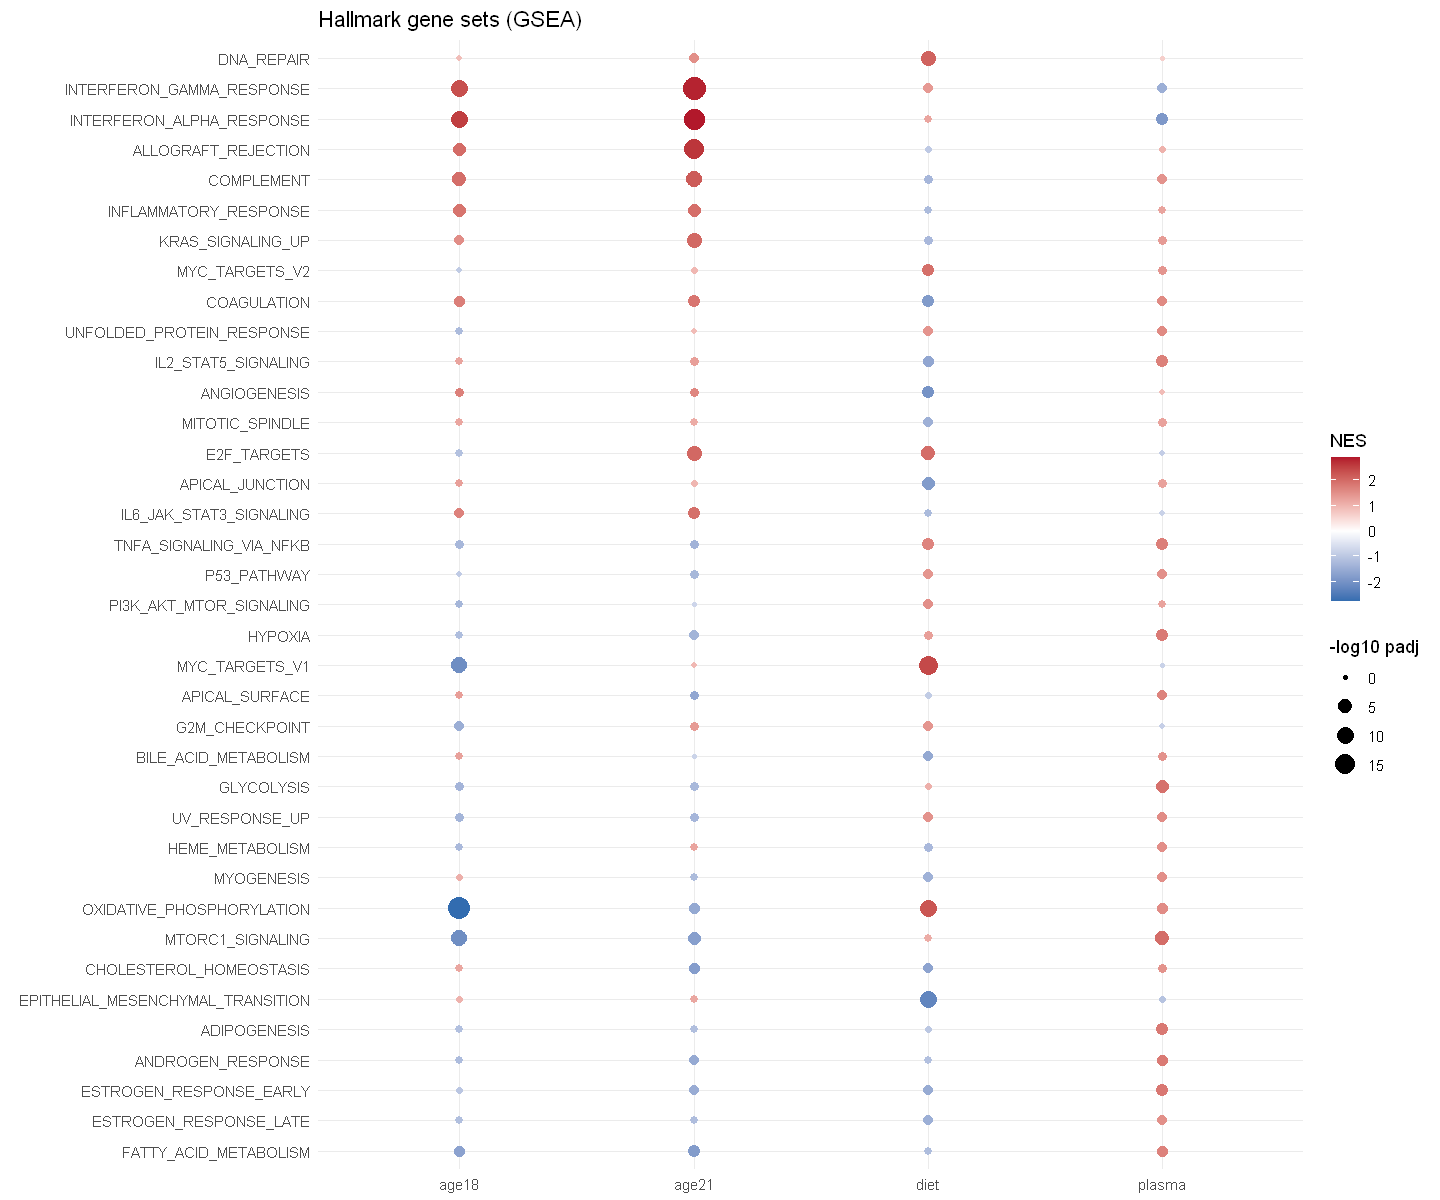

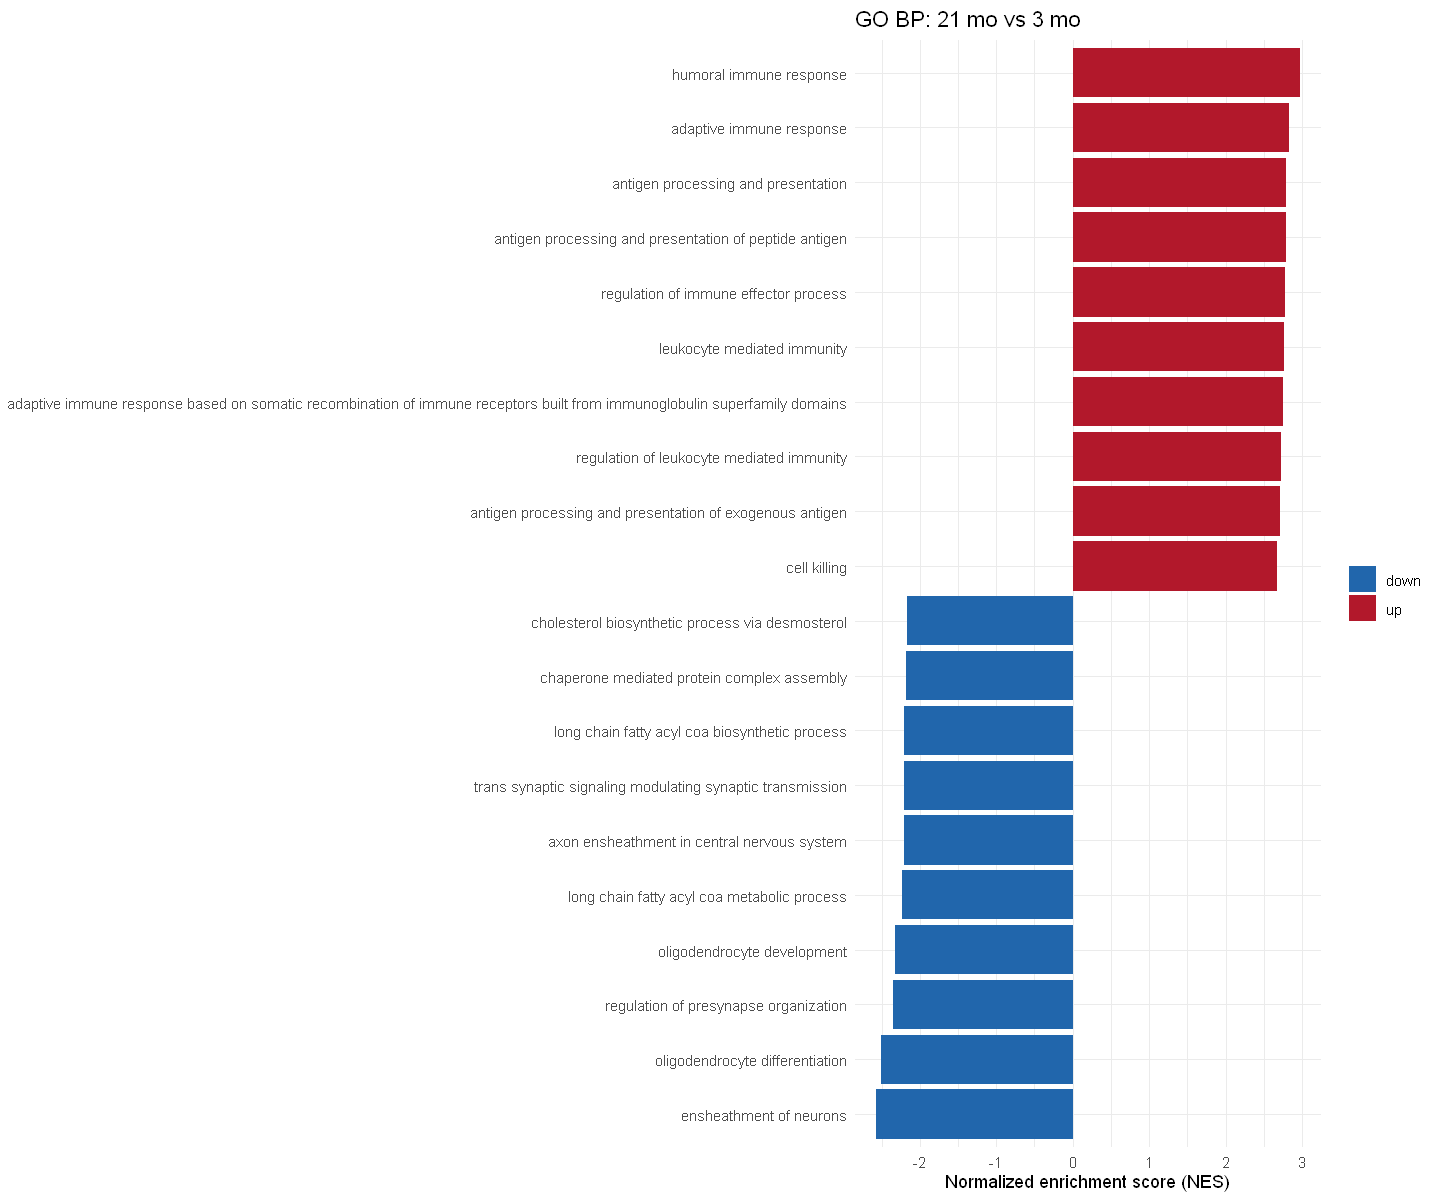

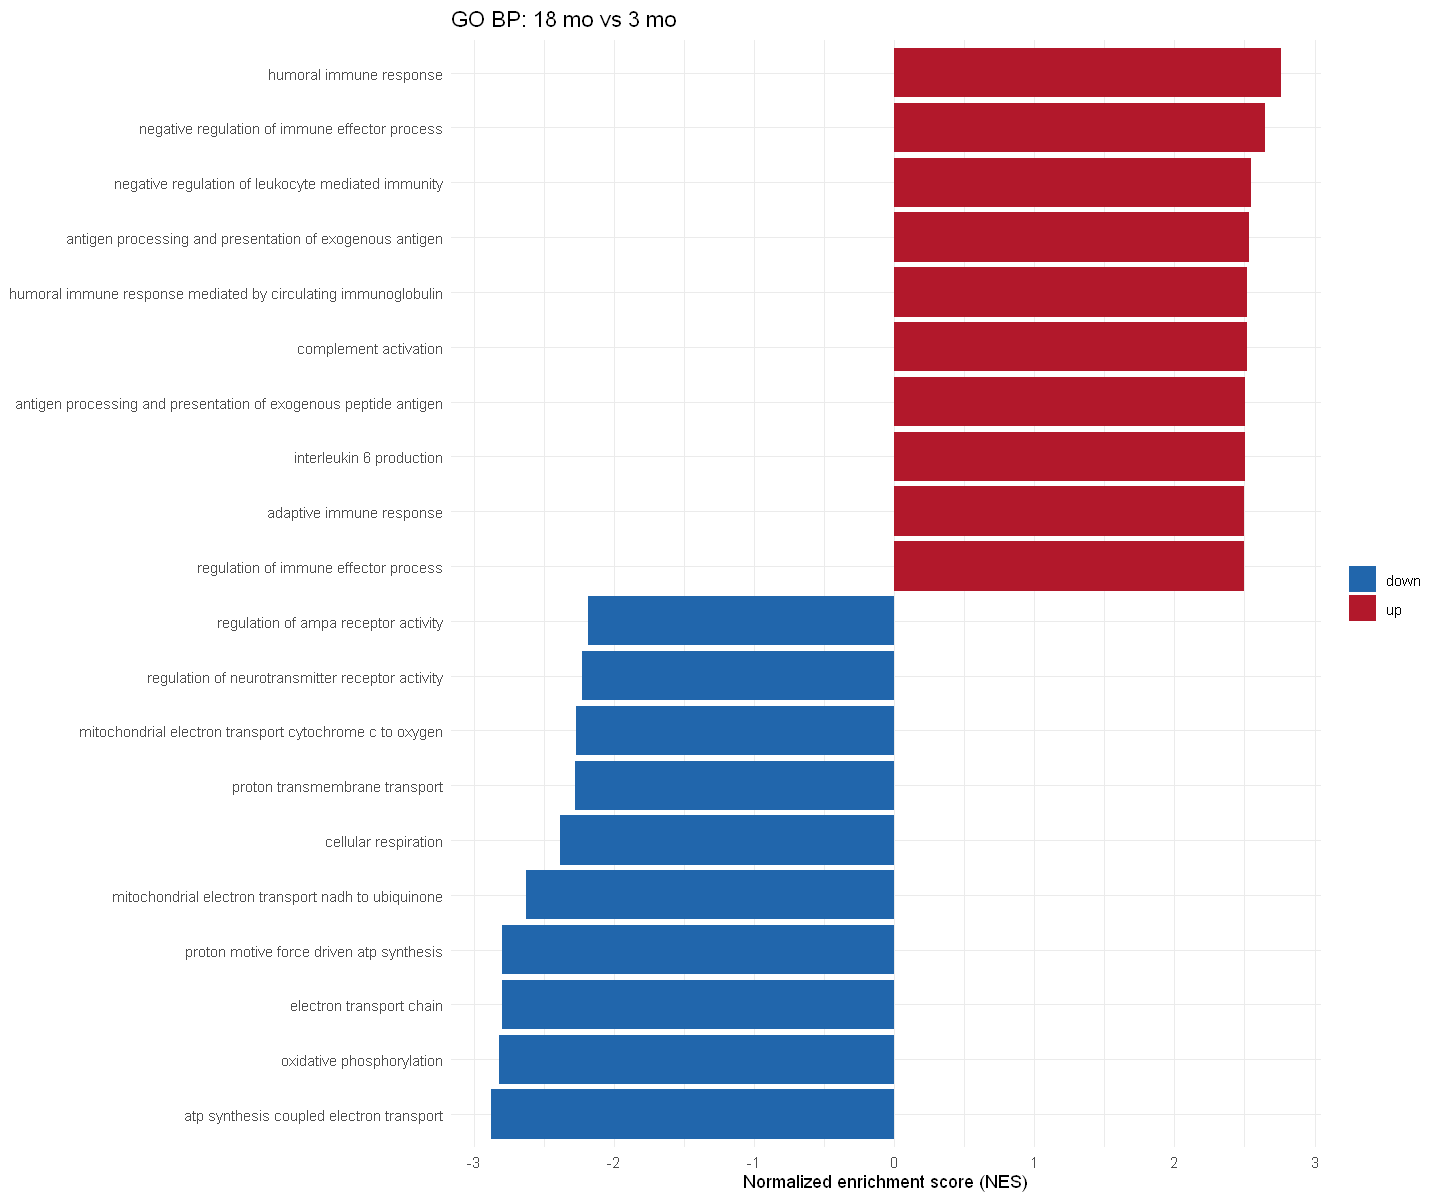

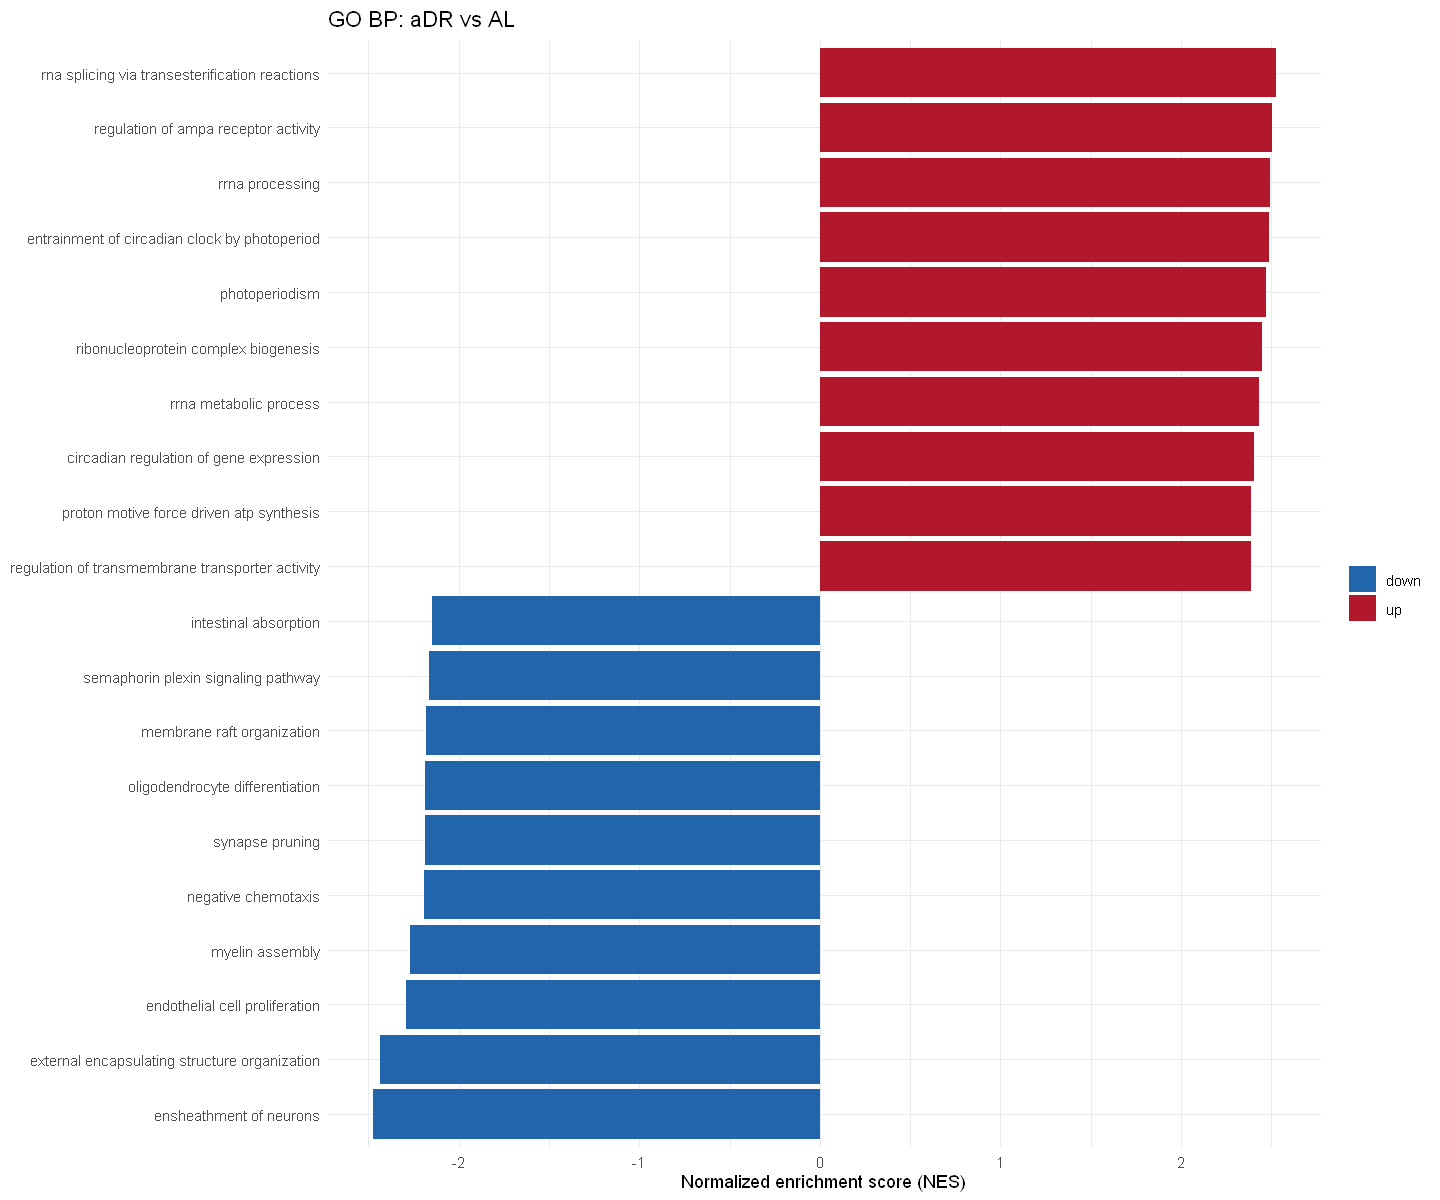

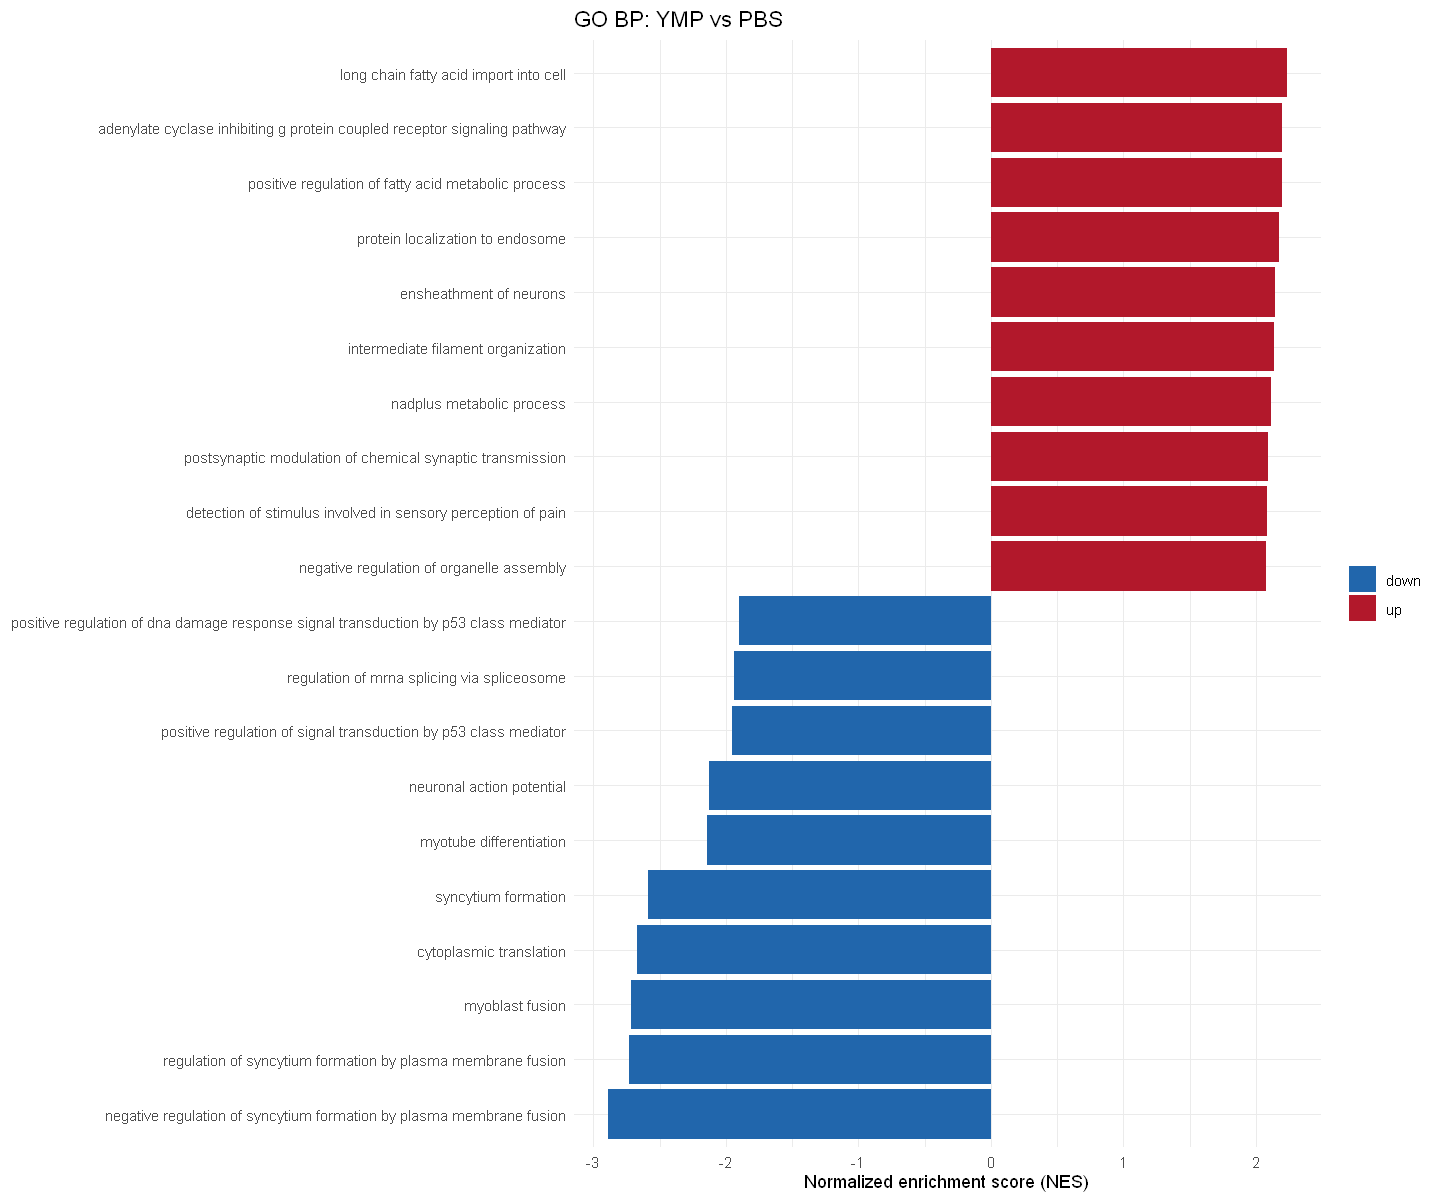

In [15]:
options(repr.plot.width = 12, repr.plot.height = 10)

# 1) Hallmark overview: NES of all comparisons side by side
nes <- do.call(rbind, lapply(names(gsea_hallmark), function(n) {
  data.frame(comparison = n, pathway = gsea_hallmark[[n]]$pathway,
             NES = gsea_hallmark[[n]]$NES, padj = gsea_hallmark[[n]]$padj)
}))
nes$pathway    <- sub("HALLMARK_", "", nes$pathway)
nes$comparison <- factor(nes$comparison, levels = names(de_list))

# keep pathways significant in at least one comparison
keep <- unique(nes$pathway[nes$padj < 0.05])

ggplot(nes[nes$pathway %in% keep, ], aes(x = comparison, y = reorder(pathway, NES))) +
  geom_point(aes(size = -log10(padj), color = NES)) +
  scale_color_gradient2(low = "#2166ac", mid = "white", high = "#b2182b") +
  labs(title = "Hallmark gene sets (GSEA)", x = NULL, y = NULL,
       size = "-log10 padj", color = "NES") +
  theme_minimal()

# 2) Top GO terms per comparison
plot_top_go <- function(gs, title, n = 10) {
  gs <- gs[gs$padj < 0.05, ]
  top <- rbind(head(gs[order(-gs$NES), ], n), head(gs[order(gs$NES), ], n))
  top <- top[!duplicated(top$pathway) & top$padj < 0.05, ]
  if (nrow(top) == 0) { message(title, ": no significant GO terms"); return(invisible(NULL)) }
  top$pathway <- tolower(gsub("_", " ", sub("GOBP_", "", top$pathway)))
  ggplot(top, aes(x = NES, y = reorder(pathway, NES), fill = NES > 0)) +
    geom_col() +
    scale_fill_manual(values = c(`TRUE` = "#b2182b", `FALSE` = "#2166ac"),
                      labels = c(`TRUE` = "up", `FALSE` = "down"), name = NULL) +
    labs(title = title, x = "Normalized enrichment score (NES)", y = NULL) +
    theme_minimal()
}

plot_top_go(gsea_gobp$age21,  "GO BP: 21 mo vs 3 mo")
plot_top_go(gsea_gobp$age18,  "GO BP: 18 mo vs 3 mo")
plot_top_go(gsea_gobp$diet,   "GO BP: aDR vs AL")
plot_top_go(gsea_gobp$plasma, "GO BP: YMP vs PBS")


−log10(padj): how significant it is

NES (normalised enrichment score: direction and strength

## Connection between interventions and aging

In [ ]:
# Join log2 fold changes of all comparisons per gene
lfc <- de_age18 %>% select(gene_id, symbol, age18 = log2FoldChange, padj_age18 = padj) %>%
  inner_join(de_age21   %>% select(gene_id, age21  = log2FoldChange, padj_age21 = padj), by = "gene_id") %>%
  inner_join(de_diet    %>% select(gene_id, diet   = log2FoldChange), by = "gene_id") %>%
  inner_join(de_plasma  %>% select(gene_id, plasma = log2FoldChange), by = "gene_id")

# Aging genes: significant in 18 vs 3 OR 21 vs 3
age_genes <- lfc %>% filter(padj_age18 < 0.05 | padj_age21 < 0.05) # age_genes are the genes that change significantly with age, in 18 vs 3 or 21 vs 3
nrow(age_genes)

# Function: summary of how an intervention relates to an aging signature
compare_to_aging <- function(age, interv) {
  ct <- cor.test(age, interv, method = "spearman", exact = FALSE)
  reversed <- sum(sign(age) != sign(interv))
  bt <- binom.test(reversed, length(age), p = 0.5)       # 50 % expected by chance
  data.frame(rho = round(ct$estimate, 3), p_cor = signif(ct$p.value, 3),
             n_genes = length(age), n_reversed = reversed,
             pct_reversed = round(100 * reversed / length(age), 1),
             p_binom = signif(bt$p.value, 3))
}

summary_tab <- rbind(
  "diet vs age18"   = compare_to_aging(age_genes$age18, age_genes$diet),
  "diet vs age21"   = compare_to_aging(age_genes$age21, age_genes$diet),
  "plasma vs age18" = compare_to_aging(age_genes$age18, age_genes$plasma),
  "plasma vs age21" = compare_to_aging(age_genes$age21, age_genes$plasma)
)
summary_tab

# Same correlation on all genes, as a background check
c(diet_all   = cor(lfc$age21, lfc$diet,   method = "spearman"),
  plasma_all = cor(lfc$age21, lfc$plasma, method = "spearman"))


[1] 306

                rho    p_cor    n_genes n_reversed pct_reversed p_binom 
diet vs age18    0.118 3.90e-02 306     152        49.7         9.54e-01
diet vs age21    0.297 1.16e-07 306     135        44.1         4.52e-02
plasma vs age18 -0.259 4.31e-06 306     187        61.1         1.21e-04
plasma vs age21 -0.352 2.26e-10 306     206        67.3         1.34e-09

  diet_all plasma_all 
 0.1223992 -0.1586568 

age_genes are the genes that change significantly with age, in 18 vs 3 or 21 vs 3 months. Only these are tested, because the question is specifically about aging genes.
rho (Spearman correlation) between the aging fold change and the intervention fold change:

Negative means rejuvenating: genes that go up with age go down under the intervention, and vice versa.

Positive means the intervention mimics aging.
≈ 0 means no relationship.

pct_reversed / p_binom: the share of aging genes whose direction the intervention flips. By chance you'd expect 50%. The binomial test checks whether the share differs significantly from 50%.

All-genes correlation: a control. If the correlation is just as strong across all genes as across the aging genes, the effect isn't specific to aging.

`geom_smooth()` using formula = 'y ~ x'


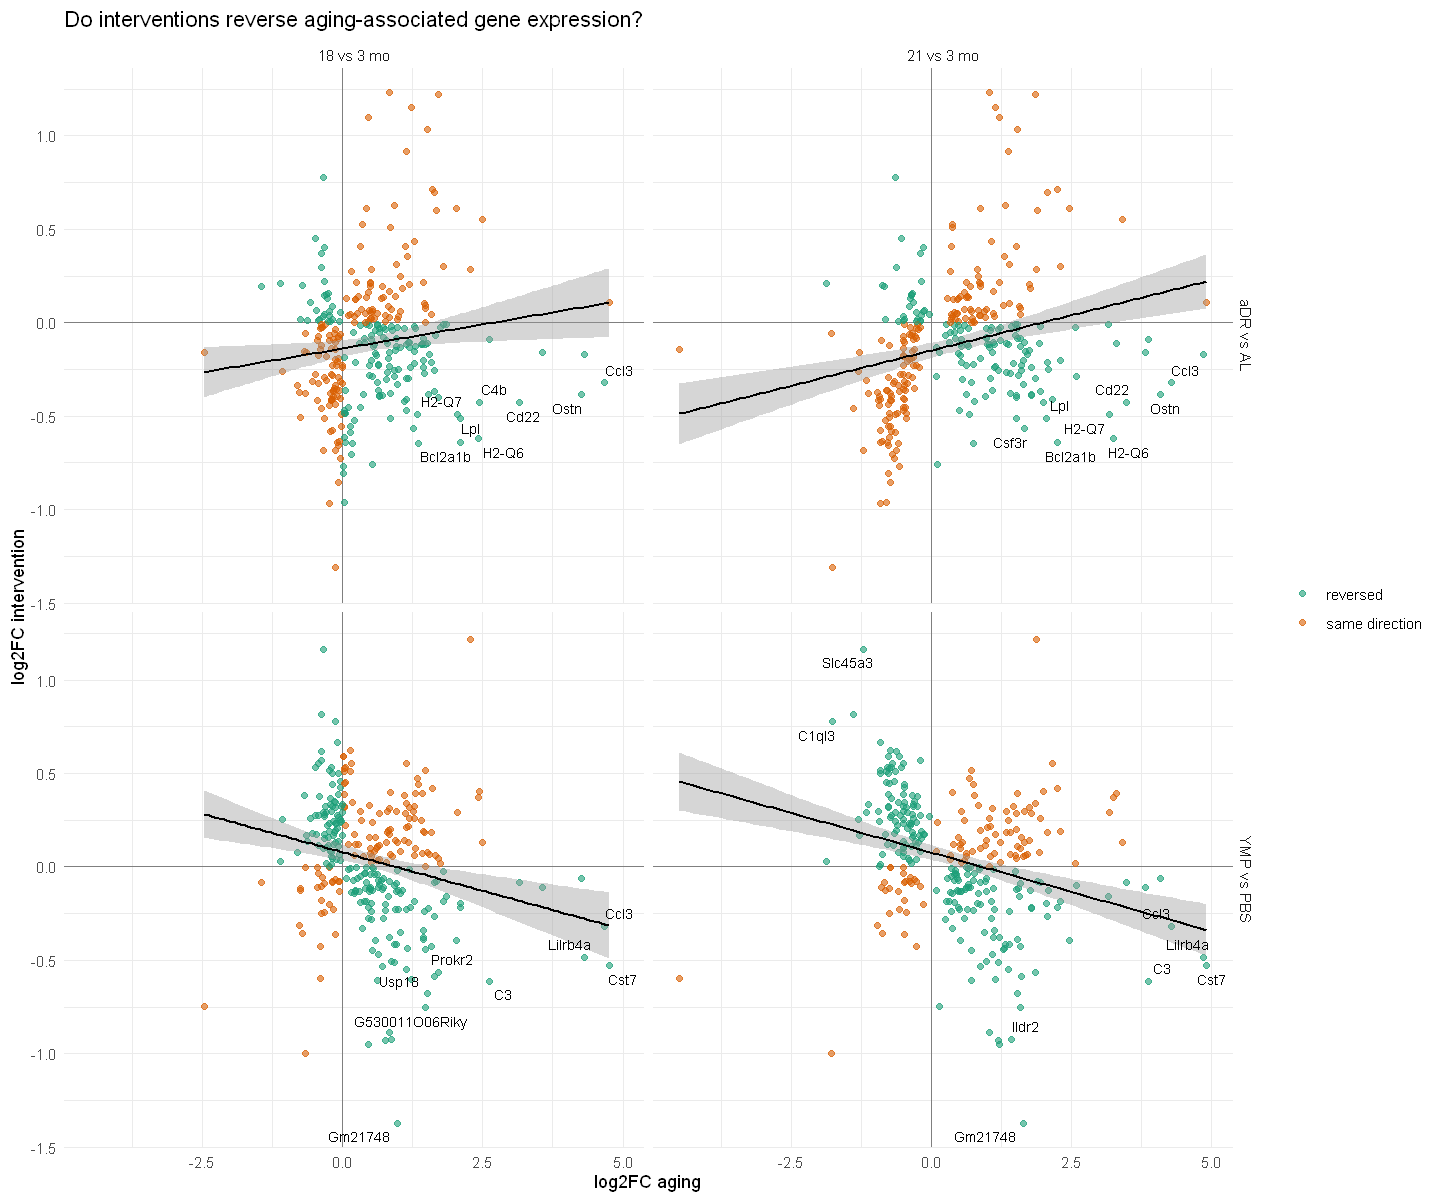

In [17]:
options(repr.plot.width = 12, repr.plot.height = 10)

# Long format: one row per gene x (aging reference, intervention)
plot_df <- rbind(
  data.frame(age_genes[, c("gene_id", "symbol")], aging = "21 vs 3 mo", interv = "aDR vs AL",
             age_lfc = age_genes$age21, int_lfc = age_genes$diet),
  data.frame(age_genes[, c("gene_id", "symbol")], aging = "21 vs 3 mo", interv = "YMP vs PBS",
             age_lfc = age_genes$age21, int_lfc = age_genes$plasma),
  data.frame(age_genes[, c("gene_id", "symbol")], aging = "18 vs 3 mo", interv = "aDR vs AL",
             age_lfc = age_genes$age18, int_lfc = age_genes$diet),
  data.frame(age_genes[, c("gene_id", "symbol")], aging = "18 vs 3 mo", interv = "YMP vs PBS",
             age_lfc = age_genes$age18, int_lfc = age_genes$plasma)
)
plot_df$effect <- ifelse(sign(plot_df$age_lfc) != sign(plot_df$int_lfc), "reversed", "same direction")

# Label the genes with the strongest reversal in each panel
lab_df <- plot_df %>% filter(effect == "reversed") %>%
  group_by(aging, interv) %>% slice_max(abs(age_lfc * int_lfc), n = 8)

ggplot(plot_df, aes(x = age_lfc, y = int_lfc)) +
  geom_hline(yintercept = 0, color = "grey50") + geom_vline(xintercept = 0, color = "grey50") +
  geom_point(aes(color = effect), alpha = 0.6, size = 1.5) +
  geom_smooth(method = "lm", se = TRUE, color = "black", linewidth = 0.6) +
  geom_text_repel(data = lab_df, aes(label = symbol), size = 3, max.overlaps = 20) +
  scale_color_manual(values = c(reversed = "#1b9e77", `same direction` = "#d95f02")) +
  facet_grid(interv ~ aging) +
  labs(x = "log2FC aging", y = "log2FC intervention", color = NULL,
       title = "Do interventions reverse aging-associated gene expression?") +
  theme_minimal()


In [18]:
# Split aging genes by direction of the aging change (21 vs 3 mo)
age_up   <- age_genes %>% filter(age21 > 0)
age_down <- age_genes %>% filter(age21 < 0)

rbind(
  "diet, genes UP with age"     = compare_to_aging(age_up$age21,   age_up$diet),
  "diet, genes DOWN with age"   = compare_to_aging(age_down$age21, age_down$diet),
  "plasma, genes UP with age"   = compare_to_aging(age_up$age21,   age_up$plasma),
  "plasma, genes DOWN with age" = compare_to_aging(age_down$age21, age_down$plasma)
)


                            rho    p_cor    n_genes n_reversed pct_reversed
diet, genes UP with age     -0.192 9.79e-03 180     106        58.9        
diet, genes DOWN with age    0.539 7.21e-11 126      29        23.0        
plasma, genes UP with age    0.035 6.42e-01 180     108        60.0        
plasma, genes DOWN with age -0.160 7.35e-02 126      98        77.8        
                            p_binom 
diet, genes UP with age     2.06e-02
diet, genes DOWN with age   9.24e-10
plasma, genes UP with age   8.90e-03
plasma, genes DOWN with age 2.69e-10

x-axis: aging change. Right means up with age.
y-axis: intervention change. Up means up under the intervention.
Green points (top-left and bottom-right quadrants) are reversed genes. Orange points (top-right and bottom-left) go in the same direction as aging.
The black line shows the overall trend. A falling line means rejuvenation.

## Overall conclusion 
Aging in the cerebellum: inflammation and immune activation go up (microglia, complement, interferon, MHC-I), and myelin and oligodendrocyte genes and energy metabolism go down. Most of this is already established by 18 months.

Young plasma shows a broad, aging-specific reversal, strongest for inflammatory microglia genes, despite few individually significant genes. Limited by n = 3.

Dietary restriction has a robust but different effect, dominated by circadian, glucocorticoid and metabolic changes. It dampens the strongest inflammation genes and restores oxidative phosphorylation, but reinforces the decline of myelin genes. Overall, not a general rejuvenation.

Limitations: two datasets (only fold changes compared, never raw values), small groups, possible feeding-time effects in aDR, and possible dissection differences in the plasma cohort.

That covers all 6 steps of your pipeline. Once the split cell has run, the analysis part is complete, and what's left is writing it up. I can help structure the report if you'd like.



